In [1]:
from pathlib import Path
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from shapely.strtree import STRtree

print("GeoPandas:", gpd.__version__)

CURRENT_FOLDER = Path.cwd()

# Find the project root by locating the data folder
PROJECT_ROOT = None

for folder in [CURRENT_FOLDER, *CURRENT_FOLDER.parents]:
    if (folder / "data" / "CAS_Data_public.csv").exists():
        PROJECT_ROOT = folder
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find the project data folder."
    )

CAS_PATH = (
    PROJECT_ROOT
    / "data"
    / "CAS_Data_public.csv"
)

ROAD_PATH = (
    PROJECT_ROOT
    / "data"
    / "road_network"
    / "National_Road_Centreline_Road_Controlling_Authority_data_-7149369423305301659.gpkg"
)

print("Project root:", PROJECT_ROOT)
print("CAS exists:", CAS_PATH.exists())
print("Road file exists:", ROAD_PATH.exists())

GeoPandas: 1.1.4
Project root: C:\Users\ASUS\Desktop\Project_Roadcrash
CAS exists: True
Road file exists: True


In [2]:
df = pd.read_csv(CAS_PATH, low_memory=False)

crash_gdf = gpd.GeoDataFrame(
    df.copy(),
    geometry=gpd.points_from_xy(df["X"], df["Y"]),
    crs="EPSG:2193"
)

print("Crash CRS:", crash_gdf.crs)
crash_gdf.head()

Crash CRS: EPSG:2193


,X,Y,OBJECTID,advisorySpeed,areaUnitID,bicycle,bridge,bus,carStationWagon,cliffBank,...,tree,truck,unknownVehicleType,urban,vanOrUtility,vehicle,waterRiver,weatherA,weatherB,geometry
0,1.764525e+06,5.912700e+06,1,NaN,520500.0,0,NaN,0,2,NaN,...,NaN,0,0,Urban,0,NaN,NaN,Light rain,Null,POINT (1764524.982 5912699.874)
1,1.841709e+06,5.793399e+06,2,NaN,535250.0,0,0.0,0,1,0.0,...,1.0,0,0,Urban,1,0.0,0.0,Heavy rain,Strong wind,POINT (1841709.484 5793398.991)
2,1.867074e+06,5.713159e+06,3,NaN,541720.0,0,NaN,0,1,NaN,...,NaN,0,0,Urban,1,NaN,NaN,Light rain,Null,POINT (1867073.746 5713158.657)
3,1.751853e+06,5.435508e+06,4,NaN,573801.0,0,NaN,0,1,NaN,...,NaN,0,0,Open,0,NaN,NaN,Heavy rain,Null,POINT (1751853.179 5435507.514)
4,1.723464e+06,6.041477e+06,5,NaN,504100.0,0,NaN,0,1,NaN,...,NaN,0,0,Urban,1,NaN,NaN,Fine,Null,POINT (1723464.164 6041476.826)


In [3]:
# Load NZTA road network
roads = gpd.read_file(ROAD_PATH)

print("Road dataset shape:", roads.shape)
print("Road CRS:", roads.crs)

if roads.crs != "EPSG:2193":
    roads = roads.to_crs("EPSG:2193")
    print("Reprojected road CRS:", roads.crs)

C:\Users\ASUS\anaconda3\Lib\site-packages\pyogrio\raw.py:200: RuntimeWarning: Non-conformant content for record 1 in column alphaModifiedDate, 2022-07-28T00:00:00.0Z, successfully parsed
  return ogr_read(
C:\Users\ASUS\anaconda3\Lib\site-packages\geopandas\io\file.py:576: UserWarning: Error parsing datetimes, original strings are returned: Out of bounds nanosecond timestamp: 2500-01-01T12:00:00Z, at position 0. You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.
  return pyogrio.read_dataframe(path_or_bytes, bbox=bbox, **kwargs)


Road dataset shape: (140717, 26)
Road CRS: EPSG:2193


In [4]:
crash_points = crash_gdf.geometry.to_numpy()
road_geoms = roads.geometry.to_numpy()

road_tree = STRtree(road_geoms)

nearest_indices, nearest_distances = road_tree.query_nearest(
    crash_points,
    return_distance=True,
    all_matches=False
)

crash_ids = nearest_indices[0]
road_ids = nearest_indices[1]

crash_gdf["dist_to_road"] = np.nan
crash_gdf["nearest_road_index"] = -1

crash_gdf.loc[
    crash_gdf.index[crash_ids],
    "dist_to_road"
] = nearest_distances

crash_gdf.loc[
    crash_gdf.index[crash_ids],
    "nearest_road_index"
] = road_ids

print("Nearest-road calculation completed.")

print("\nDistance to nearest road (metres):")
display(crash_gdf["dist_to_road"].describe())

print("Missing distances:",
      crash_gdf["dist_to_road"].isna().sum())

Nearest-road calculation completed.

Distance to nearest road (metres):


count    34866.000000
mean       880.198091
std       1685.641379
min          0.035768
25%         26.304389
50%        192.129370
75%       1020.416267
max      21913.735770
Name: dist_to_road, dtype: float64

Missing distances: 0


In [5]:
print("Road geometry types:")
print(roads.geometry.geom_type.value_counts())

print("\nRoad bounds:")
print(roads.total_bounds)

print("\nCrash bounds:")
print(crash_gdf.total_bounds)

print("\nDistance thresholds:")
for d in [10, 25, 50, 100, 250, 500, 1000, 5000]:
    count = (crash_gdf["dist_to_road"] <= d).sum()
    pct = count / len(crash_gdf) * 100
    print(f"Within {d:>4} m: {count:>6} ({pct:.2f}%)")

Road geometry types:
MultiPoint    140717
Name: count, dtype: int64

Road bounds:
[1164919.5652 4793676.9967 2465818.4983 6193445.93  ]

Crash bounds:
[1176296.3771 4794744.1496 2444710.6628 6184205.3713]

Distance thresholds:
Within   10 m:   4951 (14.20%)
Within   25 m:   8533 (24.47%)
Within   50 m:  11509 (33.01%)
Within  100 m:  14698 (42.16%)
Within  250 m:  18567 (53.25%)
Within  500 m:  22013 (63.14%)
Within 1000 m:  26045 (74.70%)
Within 5000 m:  33771 (96.86%)


In [6]:
print("Road dataset columns:\n")

for i, col in enumerate(roads.columns, 1):
    print(f"{i}. {col}")

Road dataset columns:

1. ID
2. alphaModifiedDate
3. assetCarriageWayID
4. assetCwayEndNZTMX
5. assetCwayEndNZTMY
6. assetCwayStartNZTMX
7. assetCwayStartNZTMY
8. assetRCAID
9. assetRoadID
10. carriagewayEnd
11. carriagewayStart
12. endName
13. fullRoadName
14. geomModifiedDate
15. hvyVehicleTrafficVolume
16. hvyVehicleTrafficVolumeP
17. ONRCClass
18. retiredDate
19. startName
20. surfaceType
21. trafficVolume
22. vehicleKilometresTravelled
23. width
24. TACode
25. TAName
26. geometry


In [7]:
import pyogrio
import pandas as pd

layers = pyogrio.list_layers(ROAD_PATH)

layers_df = pd.DataFrame(
    layers,
    columns=["layer_name", "geometry_type"]
)

display(layers_df)

,layer_name,geometry_type
0,ODP_RCA_Attributes,MultiPoint


## Exploratory Road Dataset Validation
This initial dataset was evaluated but excluded from final spatial modelling
because its geometry consisted of MultiPoint features rather than road
centreline geometries.

In [8]:
import requests
import geopandas as gpd
import pandas as pd
from pathlib import Path

SERVICE_URL = (
    "https://services.arcgis.com/CXBb7LAjgIIdcsPt/"
    "ArcGIS/rest/services/AMDS_NetworkModel_PROD/"
    "FeatureServer/1/query"
)

SAVE_FOLDER = PROJECT_ROOT / "data" / "amds_network"
SAVE_FOLDER.mkdir(parents=True, exist_ok=True)

all_gdfs = []

offset = 0
batch_size = 2000

while True:
    params = {
        "where": "status = 1 AND modelAssetType = 1 AND modeVehicle = 1",
        "outFields": (
            "OBJECTID,amdsIDNetworkModel,status,modelAssetType,"
            "oneway,surfaceType,assetOwnerOrganisation,"
            "dataManagingOrganisation,lifeLineRoute,"
            "modeVehicle,modeBus,modeVehicleHeavy,Shape__Length"
        ),
        "returnGeometry": "true",
        "resultOffset": offset,
        "resultRecordCount": batch_size,
        "f": "geojson"
    }

    response = requests.get(
        SERVICE_URL,
        params=params,
        timeout=120
    )

    response.raise_for_status()

    data = response.json()
    features = data.get("features", [])

    if len(features) == 0:
        break

    batch_gdf = gpd.GeoDataFrame.from_features(features)

    all_gdfs.append(batch_gdf)

    offset += len(features)

    print(f"Downloaded: {offset:,} road segments")

    if len(features) < batch_size:
        break

roads_amds = pd.concat(
    all_gdfs,
    ignore_index=True
)

roads_amds = gpd.GeoDataFrame(
    roads_amds,
    geometry="geometry",
    crs="EPSG:4326"
)

print("\nDownload complete")
print("Shape:", roads_amds.shape)
print("CRS:", roads_amds.crs)
print("Geometry types:")
print(roads_amds.geometry.geom_type.value_counts())

Downloaded: 2,000 road segments
Downloaded: 4,000 road segments
Downloaded: 6,000 road segments
Downloaded: 8,000 road segments
Downloaded: 10,000 road segments
Downloaded: 12,000 road segments
Downloaded: 14,000 road segments
Downloaded: 16,000 road segments
Downloaded: 18,000 road segments
Downloaded: 20,000 road segments
Downloaded: 22,000 road segments
Downloaded: 24,000 road segments
Downloaded: 26,000 road segments
Downloaded: 28,000 road segments
Downloaded: 30,000 road segments
Downloaded: 32,000 road segments
Downloaded: 34,000 road segments
Downloaded: 36,000 road segments
Downloaded: 38,000 road segments
Downloaded: 40,000 road segments
Downloaded: 42,000 road segments
Downloaded: 44,000 road segments
Downloaded: 46,000 road segments
Downloaded: 48,000 road segments
Downloaded: 50,000 road segments
Downloaded: 52,000 road segments
Downloaded: 54,000 road segments
Downloaded: 56,000 road segments
Downloaded: 58,000 road segments
Downloaded: 60,000 road segments
Downloaded: 62

In [9]:
# Check geometry quality
print("Total records:", len(roads_amds))
print("Missing geometry:", roads_amds.geometry.isna().sum())
print("Empty geometry:", roads_amds.geometry.is_empty.sum())

# Remove missing/empty geometries
roads_amds_clean = roads_amds[
    roads_amds.geometry.notna() &
    (~roads_amds.geometry.is_empty)
].copy()

# Convert to NZTM2000 to match CAS
roads_amds_clean = roads_amds_clean.to_crs("EPSG:2193")

print("\nClean road records:", len(roads_amds_clean))
print("New CRS:", roads_amds_clean.crs)

print("\nGeometry types:")
print(roads_amds_clean.geometry.geom_type.value_counts())

Total records: 262057
Missing geometry: 15
Empty geometry: 0

Clean road records: 262042
New CRS: EPSG:2193

Geometry types:
LineString         262033
MultiLineString         9
Name: count, dtype: int64


In [10]:
AMDS_SAVE_PATH = (
    PROJECT_ROOT
    / "data"
    / "amds_network"
    / "AMDS_vehicle_network_2193.gpkg"
)

roads_amds_clean.to_file(
    AMDS_SAVE_PATH,
    layer="amds_vehicle_network",
    driver="GPKG"
)

print("Saved successfully:")
print(AMDS_SAVE_PATH)

Saved successfully:
C:\Users\ASUS\Desktop\Project_Roadcrash\data\amds_network\AMDS_vehicle_network_2193.gpkg


In [11]:
from shapely.strtree import STRtree
import numpy as np

crash_points = crash_gdf.geometry.to_numpy()
road_lines = roads_amds_clean.geometry.to_numpy()

road_tree = STRtree(road_lines)

nearest_indices, nearest_distances = road_tree.query_nearest(
    crash_points,
    return_distance=True,
    all_matches=False
)

crash_ids = nearest_indices[0]
road_ids = nearest_indices[1]

crash_gdf["dist_to_AMDS_road"] = np.nan
crash_gdf["nearest_AMDS_road_index"] = -1

crash_gdf.loc[
    crash_gdf.index[crash_ids],
    "dist_to_AMDS_road"
] = nearest_distances

crash_gdf.loc[
    crash_gdf.index[crash_ids],
    "nearest_AMDS_road_index"
] = road_ids

print("Nearest AMDS road calculation completed.")

display(crash_gdf["dist_to_AMDS_road"].describe())

print(
    "Missing distances:",
    crash_gdf["dist_to_AMDS_road"].isna().sum()
)

Nearest AMDS road calculation completed.


count    34866.000000
mean         2.099162
std         24.415273
min          0.000057
25%          0.355010
50%          0.809112
75%          1.614278
max       1831.180503
Name: dist_to_AMDS_road, dtype: float64

Missing distances: 0


In [12]:
print("Distance thresholds:\n")

for d in [1, 2, 5, 10, 25, 50, 100, 500]:
    count = (crash_gdf["dist_to_AMDS_road"] <= d).sum()
    pct = count / len(crash_gdf) * 100
    print(f"Within {d:>3} m: {count:>6} ({pct:.2f}%)")

print("\nCrashes more than 100 m from AMDS road:")
print((crash_gdf["dist_to_AMDS_road"] > 100).sum())

print("\n10 largest distances:")
display(
    crash_gdf[
        ["X", "Y", "region", "crashSeverity", "dist_to_AMDS_road"]
    ]
    .sort_values("dist_to_AMDS_road", ascending=False)
    .head(10)
)

Distance thresholds:

Within   1 m:  20086 (57.61%)
Within   2 m:  28502 (81.75%)
Within   5 m:  33640 (96.48%)
Within  10 m:  34451 (98.81%)
Within  25 m:  34676 (99.46%)
Within  50 m:  34764 (99.71%)
Within 100 m:  34819 (99.87%)
Within 500 m:  34852 (99.96%)

Crashes more than 100 m from AMDS road:
47

10 largest distances:


,X,Y,region,crashSeverity,dist_to_AMDS_road
5145,1.769405e+06,5.416746e+06,Wellington Region,Minor Crash,1831.180503
33619,1.656922e+06,6.034643e+06,NaN,Serious Crash,1746.063300
33051,1.672357e+06,6.013505e+06,NaN,Fatal Crash,1491.231833
1830,1.432972e+06,4.971378e+06,Otago Region,Minor Crash,1406.520191
3609,1.634486e+06,6.134401e+06,NaN,Fatal Crash,1365.712875
22149,1.605822e+06,6.140931e+06,Northland Region,Serious Crash,1300.461335
9677,1.528329e+06,5.210884e+06,Canterbury Region,Serious Crash,1046.138630
6476,1.615047e+06,6.111234e+06,NaN,Minor Crash,863.927559
7817,1.732514e+06,6.018954e+06,NaN,Minor Crash,817.657567
3445,1.789043e+06,5.527599e+06,NaN,Serious Crash,626.445988


In [13]:
roads_amds_clean = roads_amds_clean.reset_index(drop=True)

road_lines = roads_amds_clean.geometry.to_numpy()
road_tree = STRtree(road_lines)

nearest_indices, nearest_distances = road_tree.query_nearest(
    crash_gdf.geometry.to_numpy(),
    return_distance=True,
    all_matches=False
)

crash_ids = nearest_indices[0]
road_ids = nearest_indices[1]

crash_gdf["dist_to_AMDS_road"] = nearest_distances
crash_gdf["nearest_AMDS_road_index"] = road_ids

print("Mapping refreshed.")
print("Missing:", crash_gdf["dist_to_AMDS_road"].isna().sum())

Mapping refreshed.
Missing: 0


In [14]:
crash_gdf["road_match_over_100m"] = (
    crash_gdf["dist_to_AMDS_road"] > 100
).astype(int)

print(
    crash_gdf["road_match_over_100m"].value_counts()
)

road_match_over_100m
0    34819
1       47
Name: count, dtype: int64


In [15]:
road_attributes = [
    "oneway",
    "surfaceType",
    "lifeLineRoute",
    "modeBus",
    "modeVehicleHeavy",
    "Shape__Length"
]

for col in road_attributes:
    crash_gdf[f"AMDS_{col}"] = (
        roads_amds_clean.iloc[
            crash_gdf["nearest_AMDS_road_index"].astype(int)
        ][col]
        .reset_index(drop=True)
    )

print("AMDS road attributes attached successfully.")

display(
    crash_gdf[
        [
            "crashSeverity",
            "dist_to_AMDS_road",
            "AMDS_oneway",
            "AMDS_surfaceType",
            "AMDS_lifeLineRoute",
            "AMDS_modeBus",
            "AMDS_modeVehicleHeavy",
            "AMDS_Shape__Length"
        ]
    ].head(10)
)

AMDS road attributes attached successfully.


,crashSeverity,dist_to_AMDS_road,AMDS_oneway,AMDS_surfaceType,AMDS_lifeLineRoute,AMDS_modeBus,AMDS_modeVehicleHeavy,AMDS_Shape__Length
0,Non-Injury Crash,0.421248,2,1.0,1.0,1.0,1.0,366.810082
1,Minor Crash,0.813598,2,1.0,0.0,1.0,1.0,359.041887
2,Non-Injury Crash,0.808976,2,1.0,0.0,1.0,1.0,249.259666
3,Non-Injury Crash,1.881117,1,1.0,0.0,0.0,1.0,6991.884155
4,Non-Injury Crash,0.288626,2,1.0,0.0,1.0,1.0,188.530901
5,Minor Crash,0.070538,2,1.0,1.0,1.0,1.0,1713.518324
6,Minor Crash,0.273298,2,1.0,0.0,1.0,1.0,3607.358986
7,Non-Injury Crash,0.228521,2,1.0,0.0,1.0,1.0,104.106940
8,Non-Injury Crash,0.437695,2,1.0,0.0,0.0,1.0,228.248601
9,Non-Injury Crash,0.307559,2,2.0,0.0,1.0,1.0,3050.113449


In [16]:
new_features = [
    "dist_to_AMDS_road",
    "AMDS_oneway",
    "AMDS_surfaceType",
    "AMDS_lifeLineRoute",
    "AMDS_modeBus",
    "AMDS_modeVehicleHeavy",
    "AMDS_Shape__Length"
]

for col in new_features:
    print("\n")
    print(col)

    print("Missing:", crash_gdf[col].isna().sum())
    print("Unique:", crash_gdf[col].nunique(dropna=True))

    print(crash_gdf[col].value_counts(dropna=False).head(15))



dist_to_AMDS_road
Missing: 0
Unique: 34863
dist_to_AMDS_road
0.210274    2
2.542576    2
1.536831    2
0.421248    1
0.257866    1
2.411859    1
0.102499    1
0.448686    1
0.323985    1
1.380878    1
3.947669    1
0.349425    1
1.594430    1
2.869995    1
1.267097    1
Name: count, dtype: int64


AMDS_oneway
Missing: 0
Unique: 3
AMDS_oneway
2    29274
1     5580
0       12
Name: count, dtype: int64


AMDS_surfaceType
Missing: 0
Unique: 4
AMDS_surfaceType
1.0    34385
2.0      456
3.0       21
4.0        4
Name: count, dtype: int64


AMDS_lifeLineRoute
Missing: 0
Unique: 2
AMDS_lifeLineRoute
0.0    30397
1.0     4469
Name: count, dtype: int64


AMDS_modeBus
Missing: 3
Unique: 2
AMDS_modeBus
1.0    22429
0.0    12434
NaN        3
Name: count, dtype: int64


AMDS_modeVehicleHeavy
Missing: 0
Unique: 2
AMDS_modeVehicleHeavy
1.0    34846
0.0       20
Name: count, dtype: int64


AMDS_Shape__Length
Missing: 0
Unique: 17905
AMDS_Shape__Length
13972.262015    137
11287.528474    137
9988.0705

In [17]:
# Calculate AMDS road-segment length in metres
# roads_amds_clean is already in EPSG:2193

roads_amds_clean["segment_length_m"] = roads_amds_clean.geometry.length

# Attach the length of each crash's nearest AMDS road segment
nearest_ids = crash_gdf["nearest_AMDS_road_index"].astype(int).to_numpy()

crash_gdf["AMDS_segment_length_m"] = (
    roads_amds_clean.iloc[nearest_ids]["segment_length_m"].to_numpy()
)

print("AMDS segment-length feature created successfully.")

print("\nMissing values:",
      crash_gdf["AMDS_segment_length_m"].isna().sum())

print("\nSegment length summary (metres):")
display(crash_gdf["AMDS_segment_length_m"].describe())

AMDS segment-length feature created successfully.

Missing values: 0

Segment length summary (metres):


count    34866.000000
mean      2886.154532
std       5005.284685
min          3.668162
25%        196.748321
50%        666.129883
75%       2913.773079
max      56277.054405
Name: AMDS_segment_length_m, dtype: float64

In [18]:
from shapely.geometry import Point
from collections import Counter

# Convert any MultiLineStrings into individual LineStrings
amds_lines = (
    roads_amds_clean
    .explode(index_parts=False)
    .reset_index(drop=True)
)

print("Road parts:", len(amds_lines))
print(amds_lines.geometry.geom_type.value_counts())

# Extract start and end coordinates from every road segment
endpoint_coords = []

for geom in amds_lines.geometry:
    if geom is None or geom.is_empty:
        continue

    coords = list(geom.coords)

    start = coords[0]
    end = coords[-1]

    # Round slightly to handle tiny coordinate precision differences
    endpoint_coords.append(
        (round(start[0], 1), round(start[1], 1))
    )
    endpoint_coords.append(
        (round(end[0], 1), round(end[1], 1))
    )

print("Total endpoints:", len(endpoint_coords))

endpoint_counts = Counter(endpoint_coords)

print("Unique endpoint locations:", len(endpoint_counts))

Road parts: 262054
LineString    262054
Name: count, dtype: int64
Total endpoints: 524108
Unique endpoint locations: 324310


In [19]:
degree_counts = Counter(endpoint_counts.values())

print("Endpoint connection frequency:\n")

for degree in sorted(degree_counts):
    print(
        f"Connected to {degree} segment(s): "
        f"{degree_counts[degree]:,} locations"
    )

Endpoint connection frequency:

Connected to 1 segment(s): 188,032 locations
Connected to 2 segment(s): 78,756 locations
Connected to 3 segment(s): 51,930 locations
Connected to 4 segment(s): 5,362 locations
Connected to 5 segment(s): 158 locations
Connected to 6 segment(s): 46 locations
Connected to 7 segment(s): 8 locations
Connected to 8 segment(s): 3 locations
Connected to 9 segment(s): 2 locations
Connected to 10 segment(s): 3 locations
Connected to 11 segment(s): 3 locations
Connected to 12 segment(s): 3 locations
Connected to 13 segment(s): 2 locations
Connected to 15 segment(s): 1 locations
Connected to 22 segment(s): 1 locations


In [20]:
from shapely.geometry import Point
from shapely.strtree import STRtree
import numpy as np

# Junction = endpoint connected to 3 or more road segments
junction_coords = [
    coord
    for coord, count in endpoint_counts.items()
    if count >= 3
]

junction_points = np.array(
    [Point(x, y) for x, y in junction_coords],
    dtype=object
)

print("Number of junction candidates:", len(junction_points))

# Build spatial index
junction_tree = STRtree(junction_points)

# Find nearest junction for every crash
nearest_junction_indices, junction_distances = (
    junction_tree.query_nearest(
        crash_gdf.geometry.to_numpy(),
        return_distance=True,
        all_matches=False
    )
)

crash_ids = nearest_junction_indices[0]
junction_ids = nearest_junction_indices[1]

# Store safely
crash_gdf["dist_to_junction_m"] = np.nan
crash_gdf["nearest_junction_index"] = -1

crash_gdf.loc[
    crash_gdf.index[crash_ids],
    "dist_to_junction_m"
] = junction_distances

crash_gdf.loc[
    crash_gdf.index[crash_ids],
    "nearest_junction_index"
] = junction_ids

print("\nDistance to nearest junction calculated.")

display(
    crash_gdf["dist_to_junction_m"].describe()
)

print(
    "Missing distances:",
    crash_gdf["dist_to_junction_m"].isna().sum()
)

Number of junction candidates: 57522

Distance to nearest junction calculated.


count    34866.000000
mean       596.398671
std       1288.364947
min          0.190377
25%         47.395803
50%        160.575159
75%        554.228637
max      29411.830956
Name: dist_to_junction_m, dtype: float64

Missing distances: 0


In [21]:
thresholds = [25, 50, 100, 250, 500, 1000]

print("Crash proximity to AMDS network junctions:\n")

for d in thresholds:
    count = (crash_gdf["dist_to_junction_m"] <= d).sum()
    pct = count / len(crash_gdf) * 100

    print(
        f"Within {d:>4} m: "
        f"{count:>6} crashes ({pct:.2f}%)"
    )

print("\nVery large junction distances:")
for d in [2000, 5000, 10000]:
    count = (crash_gdf["dist_to_junction_m"] > d).sum()
    print(f"Over {d:>5} m: {count}")

Crash proximity to AMDS network junctions:

Within   25 m:   6247 crashes (17.92%)
Within   50 m:   8957 crashes (25.69%)
Within  100 m:  13175 crashes (37.79%)
Within  250 m:  21013 crashes (60.27%)
Within  500 m:  25564 crashes (73.32%)
Within 1000 m:  29195 crashes (83.73%)

Very large junction distances:
Over  2000 m: 2804
Over  5000 m: 467
Over 10000 m: 84


In [22]:
# Create interpretable junction-proximity indicators
crash_gdf["near_junction_50m"] = (
    crash_gdf["dist_to_junction_m"] <= 50
).astype(int)

crash_gdf["near_junction_100m"] = (
    crash_gdf["dist_to_junction_m"] <= 100
).astype(int)


# Compare junction proximity across crash severity classes
junction_severity_summary = (
    crash_gdf
    .groupby("crashSeverity")
    .agg(
        crash_count=("crashSeverity", "size"),
        mean_distance_m=("dist_to_junction_m", "mean"),
        median_distance_m=("dist_to_junction_m", "median"),
        near_50m_pct=("near_junction_50m", "mean"),
        near_100m_pct=("near_junction_100m", "mean")
    )
)

# Convert proportions to percentages
junction_severity_summary["near_50m_pct"] *= 100
junction_severity_summary["near_100m_pct"] *= 100

junction_severity_summary = (
    junction_severity_summary
    .round(2)
)

display(junction_severity_summary)

,crash_count,mean_distance_m,median_distance_m,near_50m_pct,near_100m_pct
crashSeverity,,,,,
Fatal Crash,327,1392.41,638.30,11.31,16.21
Minor Crash,9997,614.67,167.05,25.70,37.44
Non-Injury Crash,22036,543.02,146.94,26.56,39.26
Serious Crash,2506,888.99,282.47,19.87,29.01


### Junction Proximity Finding

Crash severity showed a noticeable relationship with distance to the nearest
AMDS-derived network junction.

Fatal crashes had the greatest median junction distance (638.30 m), followed
by Serious crashes (282.47 m), Minor crashes (167.05 m), and Non-Injury crashes
(146.94 m).

Similarly, only 16.21% of Fatal crashes occurred within 100 m of a network
junction, compared with 29.01% of Serious crashes, 37.44% of Minor crashes,
and 39.26% of Non-Injury crashes.

This suggests that junction proximity may provide useful spatial information
for crash-severity classification. However, the relationship should not be
interpreted as causal because junction distance may also reflect other
characteristics such as rurality, road type, and speed environment.

In [23]:
from scipy.stats import kruskal

severity_order = [
    "Non-Injury Crash",
    "Minor Crash",
    "Serious Crash",
    "Fatal Crash"
]

groups = [
    crash_gdf.loc[
        crash_gdf["crashSeverity"] == severity,
        "dist_to_junction_m"
    ].dropna()
    for severity in severity_order
]

H, p = kruskal(*groups)

print("Kruskal-Wallis test")
print(f"H statistic: {H:.4f}")
print(f"p-value: {p:.6g}")

if p < 0.05:
    print("Result: Junction-distance distributions differ significantly across severity classes.")
else:
    print("Result: No statistically significant difference was detected.")

Kruskal-Wallis test
H statistic: 364.6439
p-value: 1.00609e-78
Result: Junction-distance distributions differ significantly across severity classes.


In [24]:
# Kruskal-Wallis effect size: epsilon-squared

N = len(crash_gdf)
k = crash_gdf["crashSeverity"].nunique()

epsilon_squared = (H - k + 1) / (N - k)

print(f"Epsilon-squared: {epsilon_squared:.4f}")

if epsilon_squared < 0.01:
    interpretation = "very small"
elif epsilon_squared < 0.06:
    interpretation = "small"
elif epsilon_squared < 0.14:
    interpretation = "moderate"
else:
    interpretation = "large"

print("Approximate effect:", interpretation)

Epsilon-squared: 0.0104
Approximate effect: small


In [25]:
# Create CAS + Spatial modelling dataset

baseline_features = [
    "bicycle",
    "bus",
    "carStationWagon",
    "crashDirectionDescription",
    "crashFinancialYear",
    "crashSHDescription",
    "crashYear",
    "directionRoleDescription",
    "flatHill",
    "light",
    "moped",
    "motorcycle",
    "NumberOfLanes",
    "otherVehicleType",
    "region",
    "roadCharacter",
    "roadLane",
    "roadSurface",
    "schoolBus",
    "speedLimit",
    "streetLight",
    "suv",
    "taxi",
    "trafficControl",
    "truck",
    "unknownVehicleType",
    "urban",
    "vanOrUtility",
    "weatherA",
    "weatherB"
]

spatial_features = [
    "dist_to_junction_m",
    "AMDS_oneway",
    "AMDS_surfaceType",
    "AMDS_lifeLineRoute",
    "AMDS_modeBus",
    "AMDS_segment_length_m"
]

target = "crashSeverity"

spatial_model_df = crash_gdf[
    baseline_features + spatial_features + [target]
].copy()

print("Spatial modelling dataset shape:", spatial_model_df.shape)
print("CAS baseline predictors:", len(baseline_features))
print("Added spatial predictors:", len(spatial_features))
print("Total predictors:", len(baseline_features) + len(spatial_features))

print("\nTarget distribution:")
print(spatial_model_df[target].value_counts())

print("\nMissing values in spatial features:")
print(spatial_model_df[spatial_features].isna().sum())

Spatial modelling dataset shape: (34866, 37)
CAS baseline predictors: 30
Added spatial predictors: 6
Total predictors: 36

Target distribution:
crashSeverity
Non-Injury Crash    22036
Minor Crash          9997
Serious Crash        2506
Fatal Crash           327
Name: count, dtype: int64

Missing values in spatial features:
dist_to_junction_m       0
AMDS_oneway              0
AMDS_surfaceType         0
AMDS_lifeLineRoute       0
AMDS_modeBus             3
AMDS_segment_length_m    0
dtype: int64


In [26]:
from sklearn.model_selection import train_test_split

# Spatial variables that are categorical even though some are stored as numbers
spatial_categorical = [
    "AMDS_oneway",
    "AMDS_surfaceType",
    "AMDS_lifeLineRoute",
    "AMDS_modeBus"
]

# Original categorical CAS predictors used in baseline
baseline_categorical = [
    "crashDirectionDescription",
    "crashFinancialYear",
    "crashSHDescription",
    "directionRoleDescription",
    "flatHill",
    "light",
    "region",
    "roadCharacter",
    "roadLane",
    "roadSurface",
    "streetLight",
    "trafficControl",
    "urban",
    "weatherA",
    "weatherB"
]

categorical_features = (
    baseline_categorical +
    spatial_categorical
)

numeric_features = [
    col for col in baseline_features + spatial_features
    if col not in categorical_features
]

X_spatial = spatial_model_df[
    baseline_features + spatial_features
].copy()

y_spatial = spatial_model_df["crashSeverity"].copy()

X_train_spatial, X_test_spatial, y_train_spatial, y_test_spatial = (
    train_test_split(
        X_spatial,
        y_spatial,
        test_size=0.20,
        random_state=42,
        stratify=y_spatial
    )
)

print("Training shape:", X_train_spatial.shape)
print("Test shape:", X_test_spatial.shape)

print("\nNumeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

print("\nTraining target distribution:")
print(y_train_spatial.value_counts())

print("\nTest target distribution:")
print(y_test_spatial.value_counts())

Training shape: (27892, 36)
Test shape: (6974, 36)

Numeric features: 17
Categorical features: 19

Training target distribution:
crashSeverity
Non-Injury Crash    17628
Minor Crash          7997
Serious Crash        2005
Fatal Crash           262
Name: count, dtype: int64

Test target distribution:
crashSeverity
Non-Injury Crash    4408
Minor Crash         2000
Serious Crash        501
Fatal Crash           65
Name: count, dtype: int64


In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numeric preprocessing
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Combine preprocessing
spatial_preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Fit only on training data
X_train_spatial_processed = spatial_preprocessor.fit_transform(
    X_train_spatial
)

# Apply same transformation to test data
X_test_spatial_processed = spatial_preprocessor.transform(
    X_test_spatial
)

print("Processed training shape:",
      X_train_spatial_processed.shape)

print("Processed test shape:",
      X_test_spatial_processed.shape)

print("\nOriginal predictors:", X_train_spatial.shape[1])
print(
    "Processed features after one-hot encoding:",
    X_train_spatial_processed.shape[1]
)

Processed training shape: (27892, 107)
Processed test shape: (6974, 107)

Original predictors: 36
Processed features after one-hot encoding: 107


In [28]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

# Encode target labels
label_encoder_spatial = LabelEncoder()

y_train_spatial_encoded = label_encoder_spatial.fit_transform(
    y_train_spatial
)

y_test_spatial_encoded = label_encoder_spatial.transform(
    y_test_spatial
)

print("Class mapping:")
for i, label in enumerate(label_encoder_spatial.classes_):
    print(i, "=", label)

# Balanced sample weights
spatial_sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train_spatial_encoded
)

# Same XGBoost configuration as CAS-only baseline
weighted_xgb_spatial = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

weighted_xgb_spatial.fit(
    X_train_spatial_processed,
    y_train_spatial_encoded,
    sample_weight=spatial_sample_weights
)

# Predictions
y_pred_spatial = weighted_xgb_spatial.predict(
    X_test_spatial_processed
)

# Metrics
spatial_accuracy = accuracy_score(
    y_test_spatial_encoded,
    y_pred_spatial
)

spatial_balanced_accuracy = balanced_accuracy_score(
    y_test_spatial_encoded,
    y_pred_spatial
)

spatial_macro_f1 = f1_score(
    y_test_spatial_encoded,
    y_pred_spatial,
    average="macro"
)

print("\nCAS + Spatial Weighted XGBoost")
print(f"Accuracy:          {spatial_accuracy:.4f}")
print(f"Balanced Accuracy: {spatial_balanced_accuracy:.4f}")
print(f"Macro F1:          {spatial_macro_f1:.4f}")

print("\nClassification Report:\n")

print(
    classification_report(
        y_test_spatial_encoded,
        y_pred_spatial,
        target_names=label_encoder_spatial.classes_,
        digits=4
    )
)

Class mapping:
0 = Fatal Crash
1 = Minor Crash
2 = Non-Injury Crash
3 = Serious Crash

CAS + Spatial Weighted XGBoost
Accuracy:          0.5083
Balanced Accuracy: 0.4021
Macro F1:          0.3364

Classification Report:

                  precision    recall  f1-score   support

     Fatal Crash     0.0359    0.2615    0.0632        65
     Minor Crash     0.3612    0.3785    0.3696      2000
Non-Injury Crash     0.7664    0.5851    0.6636      4408
   Serious Crash     0.1846    0.3832    0.2492       501

        accuracy                         0.5083      6974
       macro avg     0.3370    0.4021    0.3364      6974
    weighted avg     0.6016    0.5083    0.5439      6974



### Spatial Feature Experiment - Weighted XGBoost Result

Adding six AMDS-derived spatial and road-network features produced a modest
improvement in overall multiclass performance.

The CAS-only Weighted XGBoost achieved:

- Accuracy: 0.4900
- Balanced Accuracy: 0.4076
- Macro F1: 0.3272

After adding the spatial features, performance changed to:

- Accuracy: 0.5083
- Balanced Accuracy: 0.4021
- Macro F1: 0.3364

Macro F1 increased from 0.3272 to 0.3364, while overall accuracy increased
from 49.00% to 50.83%. However, balanced accuracy decreased slightly.

The spatial model achieved recalls of 26.15% for Fatal crashes and 38.32% for
Serious crashes. Therefore, the added spatial information improved overall
class-balanced F1 performance but did not improve the detection of every
minority severity class.

These results suggest that AMDS spatial and road-network features provide
additional predictive information, although their contribution is modest.

In [29]:
comparison = pd.DataFrame({
    "Model": [
        "CAS-only Weighted XGBoost",
        "CAS + Spatial Weighted XGBoost"
    ],
    "Accuracy": [
        0.4900,
        spatial_accuracy
    ],
    "Balanced Accuracy": [
        0.4076,
        spatial_balanced_accuracy
    ],
    "Macro F1": [
        0.3272,
        spatial_macro_f1
    ]
})

comparison["Macro F1 Change"] = (
    comparison["Macro F1"] - 0.3272
)

display(comparison.round(4))

,Model,Accuracy,Balanced Accuracy,Macro F1,Macro F1 Change
0,CAS-only Weighted XGBoost,0.4900,0.4076,0.3272,0.0000
1,CAS + Spatial Weighted XGBoost,0.5083,0.4021,0.3364,0.0092


In [30]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)
from xgboost import XGBClassifier
import pandas as pd

junction_features = [
    "dist_to_junction_m"
]

road_attribute_features = [
    "AMDS_oneway",
    "AMDS_surfaceType",
    "AMDS_lifeLineRoute",
    "AMDS_modeBus",
    "AMDS_segment_length_m"
]


def evaluate_spatial_subset(experiment_name, added_features):
    feature_list = baseline_features + added_features

    categorical_list = [
        col for col in feature_list
        if col in baseline_categorical + spatial_categorical
    ]

    numeric_list = [
        col for col in feature_list
        if col not in categorical_list
    ]

    # Preserve the existing split and row order.
    X_train_subset = X_train_spatial[feature_list].copy()
    X_test_subset = X_test_spatial[feature_list].copy()

    num_transformer = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    cat_transformer = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    subset_preprocessor = ColumnTransformer([
        ("num", num_transformer, numeric_list),
        ("cat", cat_transformer, categorical_list)
    ])

    X_train_processed = subset_preprocessor.fit_transform(
        X_train_subset
    )
    X_test_processed = subset_preprocessor.transform(
        X_test_subset
    )

    sample_weights = compute_sample_weight(
        class_weight="balanced",
        y=y_train_spatial_encoded
    )

    model = XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softprob",
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        X_train_processed,
        y_train_spatial_encoded,
        sample_weight=sample_weights
    )

    predictions = model.predict(X_test_processed)

    return {
        "Experiment": experiment_name,
        "Predictors": len(feature_list),
        "Accuracy": accuracy_score(
            y_test_spatial_encoded, predictions
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test_spatial_encoded, predictions
        ),
        "Macro F1": f1_score(
            y_test_spatial_encoded,
            predictions,
            average="macro",
            zero_division=0
        )
    }


experiment_definitions = [
    ("CAS Only", []),
    ("CAS + Junction Distance", junction_features),
    ("CAS + Road Attributes", road_attribute_features),
    ("CAS + All Spatial", spatial_features)
]

ablation_results = [
    evaluate_spatial_subset(experiment_name, added_features)
    for experiment_name, added_features in experiment_definitions
]

ablation_table = pd.DataFrame(ablation_results)

baseline_row = ablation_table.loc[
    ablation_table["Experiment"].eq("CAS Only")
].iloc[0].to_dict()

ablation_table["Macro F1 Change"] = (
    ablation_table["Macro F1"] - baseline_row["Macro F1"]
)

display(ablation_table.round(4))

print(
    "\nAll configurations use the same seed-42 train/test records, "
    "preprocessing strategies, class weighting and XGBoost settings."
)
print(
    "Macro F1 Change is calculated from the unrounded, "
    "retrained CAS-only baseline."
)

,Experiment,Predictors,Accuracy,Balanced Accuracy,Macro F1,Macro F1 Change
0,CAS Only,30,0.4900,0.4076,0.3272,0.0000
1,CAS + Junction Distance,31,0.5067,0.3999,0.3376,0.0104
2,CAS + Road Attributes,35,0.5047,0.3919,0.3317,0.0045
3,CAS + All Spatial,36,0.5083,0.4021,0.3364,0.0092



All configurations use the same seed-42 train/test records, preprocessing strategies, class weighting and XGBoost settings.
Macro F1 Change is calculated from the unrounded, retrained CAS-only baseline.


### Spatial Feature Ablation Finding

The ablation experiment showed that junction proximity provided the strongest
individual contribution among the tested spatial features.

The CAS-only Weighted XGBoost achieved a Macro F1 of 0.3272. Adding only
distance to the nearest AMDS-derived junction increased Macro F1 to 0.3376,
an improvement of 0.0104.

Adding the AMDS road attributes without junction distance produced a smaller
improvement (Macro F1 = 0.3317). Combining all spatial features resulted in
a Macro F1 of 0.3364, which was slightly lower than the junction-distance-only
model.

This indicates that the improvement was primarily associated with junction
proximity rather than the complete set of road-network attributes.

However, Balanced Accuracy did not improve over the CAS-only baseline.
Therefore, the spatial contribution is considered modest and metric-dependent.

In [31]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    recall_score
)
from xgboost import XGBClassifier

import pandas as pd
import numpy as np

# Robustness experiment settings

seeds = [42, 7, 21, 84, 123]

junction_only_features = baseline_features + [
    "dist_to_junction_m"
]

# Fixed target encoder
robustness_encoder = LabelEncoder()
robustness_encoder.fit(crash_gdf["crashSeverity"])

print("Class mapping:")
for i, label in enumerate(robustness_encoder.classes_):
    print(i, "=", label)

fatal_id = list(robustness_encoder.classes_).index("Fatal Crash")
serious_id = list(robustness_encoder.classes_).index("Serious Crash")

# Function to train one experiment for one seed

def run_seed_experiment(feature_list, model_name, seed):

    X = crash_gdf[feature_list].copy()
    y = crash_gdf["crashSeverity"].copy()

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=seed,
        stratify=y
    )

    # Determine categorical/numeric variables
    categorical_list = [
        col for col in feature_list
        if col in baseline_categorical + spatial_categorical
    ]

    numeric_list = [
        col for col in feature_list
        if col not in categorical_list
    ]

    # Preprocessing
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer([
        ("num", numeric_pipeline, numeric_list),
        ("cat", categorical_pipeline, categorical_list)
    ])

    X_train_processed = preprocessor.fit_transform(X_train)
    X_test_processed = preprocessor.transform(X_test)

    # Encode target
    y_train_encoded = robustness_encoder.transform(y_train)
    y_test_encoded = robustness_encoder.transform(y_test)

    # Balanced sample weights
    sample_weights = compute_sample_weight(
        class_weight="balanced",
        y=y_train_encoded
    )

    # Same Weighted XGBoost configuration
    model = XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softprob",
        eval_metric="mlogloss",
        random_state=seed,
        n_jobs=-1
    )

    model.fit(
        X_train_processed,
        y_train_encoded,
        sample_weight=sample_weights
    )

    predictions = model.predict(X_test_processed)

    fatal_recall = recall_score(
        y_test_encoded,
        predictions,
        labels=[fatal_id],
        average=None
    )[0]

    serious_recall = recall_score(
        y_test_encoded,
        predictions,
        labels=[serious_id],
        average=None
    )[0]

    return {
        "Model": model_name,
        "Seed": seed,
        "Accuracy": accuracy_score(
            y_test_encoded,
            predictions
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test_encoded,
            predictions
        ),
        "Macro F1": f1_score(
            y_test_encoded,
            predictions,
            average="macro"
        ),
        "Fatal Recall": fatal_recall,
        "Serious Recall": serious_recall
    }

# Run experiments

robustness_results = []

for seed in seeds:

    print(f"\nRunning seed {seed}...")

    baseline_result = run_seed_experiment(
        baseline_features,
        "CAS Only",
        seed
    )

    robustness_results.append(baseline_result)

    junction_result = run_seed_experiment(
        junction_only_features,
        "CAS + Junction Distance",
        seed
    )

    robustness_results.append(junction_result)


robustness_df = pd.DataFrame(robustness_results)

print("\nCompleted all robustness runs.")

display(
    robustness_df.round(4)
)

Class mapping:
0 = Fatal Crash
1 = Minor Crash
2 = Non-Injury Crash
3 = Serious Crash

Running seed 42...

Running seed 7...

Running seed 21...

Running seed 84...

Running seed 123...

Completed all robustness runs.


,Model,Seed,Accuracy,Balanced Accuracy,Macro F1,Fatal Recall,Serious Recall
0,CAS Only,42,0.4900,0.4076,0.3272,0.3231,0.3892
1,CAS + Junction Distance,42,0.5067,0.3999,0.3376,0.2308,0.4032
2,CAS Only,7,0.4920,0.4111,0.3284,0.3385,0.3892
3,CAS + Junction Distance,7,0.4977,0.3921,0.3268,0.2615,0.3673
4,CAS Only,21,0.4991,0.4217,0.3351,0.3538,0.4012
5,CAS + Junction Distance,21,0.5152,0.4071,0.3394,0.2769,0.3812
6,CAS Only,84,0.4971,0.4024,0.3315,0.2615,0.4172
7,CAS + Junction Distance,84,0.5040,0.3944,0.3325,0.2308,0.3912
8,CAS Only,123,0.4918,0.3881,0.3219,0.2615,0.3752
9,CAS + Junction Distance,123,0.4978,0.3789,0.3251,0.2000,0.3792


In [32]:
robustness_summary = (
    robustness_df
    .groupby("Model")
    .agg({
        "Accuracy": ["mean", "std"],
        "Balanced Accuracy": ["mean", "std"],
        "Macro F1": ["mean", "std"],
        "Fatal Recall": ["mean", "std"],
        "Serious Recall": ["mean", "std"]
    })
)

display(
    robustness_summary.round(4)
)

Accuracy         Balanced Accuracy         Macro F1  \
                            mean     std              mean     std     mean   
Model                                                                         
CAS + Junction Distance   0.5043  0.0072            0.3945  0.0105   0.3323   
CAS Only                  0.4940  0.0039            0.4062  0.0123   0.3288   

                                Fatal Recall         Serious Recall          
                            std         mean     std           mean     std  
Model                                                                        
CAS + Junction Distance  0.0063       0.2400  0.0300         0.3844  0.0135  
CAS Only                 0.0049       0.3077  0.0435         0.3944  0.0157

In [33]:
macro_f1_comparison = robustness_df.pivot(
    index="Seed",
    columns="Model",
    values="Macro F1"
)

macro_f1_comparison["Junction Improvement"] = (
    macro_f1_comparison["CAS + Junction Distance"]
    - macro_f1_comparison["CAS Only"]
)

display(macro_f1_comparison.round(4))

print(
    "\nMean Macro F1 improvement:",
    round(
        macro_f1_comparison["Junction Improvement"].mean(),
        4
    )
)

print(
    "Seeds where junction model improved:",
    (
        macro_f1_comparison["Junction Improvement"] > 0
    ).sum(),
    "out of",
    len(macro_f1_comparison)
)

Model,CAS + Junction Distance,CAS Only,Junction Improvement
Seed,,,
7,0.3268,0.3284,-0.0016
21,0.3394,0.3351,0.0043
42,0.3376,0.3272,0.0104
84,0.3325,0.3315,0.0010
123,0.3251,0.3219,0.0032



Mean Macro F1 improvement: 0.0034
Seeds where junction model improved: 4 out of 5


### Multi-Seed Robustness of Junction Distance

The spatial experiment was repeated using five random train/test splits
(seeds 42, 7, 21, 84, and 123) to determine whether the improvement from
junction distance was dependent on a single split.

The CAS-only model achieved a mean Macro F1 of 0.3288, while adding distance
to the nearest AMDS-derived junction increased mean Macro F1 to 0.3323.

Junction distance improved Macro F1 in four of the five random seeds, with a
mean improvement of approximately 0.0034.

Mean accuracy also increased from 0.4940 to 0.5043.

However, Balanced Accuracy decreased from 0.4062 to 0.3945. Mean Fatal-crash
recall decreased from 0.3077 to 0.2400, while Serious-crash recall decreased
slightly from 0.3944 to 0.3844.

Therefore, junction proximity provides a small and reasonably consistent
improvement in overall Macro F1, but it does not improve the detection of the
most severe crash classes. The usefulness of the spatial feature is therefore
metric-dependent.

In [34]:
traffic_columns = [
    "trafficVolume",
    "hvyVehicleTrafficVolume",
    "hvyVehicleTrafficVolumeP",
    "vehicleKilometresTravelled",
    "width",
    "ONRCClass",
    "surfaceType",
    "fullRoadName",
    "assetCwayStartNZTMX",
    "assetCwayStartNZTMY",
    "assetCwayEndNZTMX",
    "assetCwayEndNZTMY"
]

print("RCA traffic/road attribute dataset shape:", roads.shape)

print("\nMissing values:")
print(
    roads[traffic_columns]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

print("\nTraffic Volume summary:")
display(roads["trafficVolume"].describe())

print("\nHeavy Vehicle Traffic Volume summary:")
display(roads["hvyVehicleTrafficVolume"].describe())

print("\nHeavy Vehicle Percentage summary:")
display(roads["hvyVehicleTrafficVolumeP"].describe())

print("\nONRC classes:")
print(
    roads["ONRCClass"]
    .value_counts(dropna=False)
    .head(20)
)

RCA traffic/road attribute dataset shape: (140717, 26)

Missing values:
hvyVehicleTrafficVolume       30288
hvyVehicleTrafficVolumeP      30288
ONRCClass                     19222
trafficVolume                 17129
vehicleKilometresTravelled    17129
width                           674
surfaceType                     674
fullRoadName                      0
assetCwayStartNZTMX               0
assetCwayStartNZTMY               0
assetCwayEndNZTMX                 0
assetCwayEndNZTMY                 0
dtype: int64

Traffic Volume summary:


count    123588.000000
mean       1917.514500
std        4853.147028
min           1.000000
25%          69.000000
50%         230.000000
75%        1242.000000
max      111793.000000
Name: trafficVolume, dtype: float64


Heavy Vehicle Traffic Volume summary:


count    110429.000000
mean        169.305291
std         420.209311
min           1.000000
25%           6.000000
50%          20.000000
75%         114.000000
max       13782.000000
Name: hvyVehicleTrafficVolume, dtype: float64


Heavy Vehicle Percentage summary:


count    110429.000000
mean          9.415249
std           7.272587
min           0.200000
25%           5.000000
50%           7.000000
75%          11.900000
max         234.600000
Name: hvyVehicleTrafficVolumeP, dtype: float64


ONRC classes:
ONRCClass
Low Volume             40669
Access                 31214
Secondary Collector    20830
None                   19222
Primary Collector      10749
Arterial                6797
Not Required            4651
Regional                2780
High Volume             2494
National                1311
Name: count, dtype: int64


In [35]:
# Traffic/exposure data-quality checks

print("Heavy vehicle percentage > 100:")
print((roads["hvyVehicleTrafficVolumeP"] > 100).sum())

print("\nHeavy vehicle volume greater than total traffic volume:")
valid_volume = roads[
    roads["trafficVolume"].notna() &
    roads["hvyVehicleTrafficVolume"].notna()
]

print(
    (
        valid_volume["hvyVehicleTrafficVolume"] >
        valid_volume["trafficVolume"]
    ).sum()
)

print("\nHeavy vehicle percentage quantiles:")
display(
    roads["hvyVehicleTrafficVolumeP"].quantile(
        [0, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1.00]
    )
)

print("\nLargest heavy-vehicle percentage records:")
display(
    roads[
        [
            "fullRoadName",
            "trafficVolume",
            "hvyVehicleTrafficVolume",
            "hvyVehicleTrafficVolumeP",
            "ONRCClass"
        ]
    ]
    .sort_values(
        "hvyVehicleTrafficVolumeP",
        ascending=False
    )
    .head(15)
)

Heavy vehicle percentage > 100:
1

Heavy vehicle volume greater than total traffic volume:
1

Heavy vehicle percentage quantiles:


0.00      0.2
0.25      5.0
0.50      7.0
0.75     11.9
0.90     18.3
0.95     21.7
0.99     36.0
1.00    234.6
Name: hvyVehicleTrafficVolumeP, dtype: float64


Largest heavy-vehicle percentage records:


,fullRoadName,trafficVolume,hvyVehicleTrafficVolume,hvyVehicleTrafficVolumeP,ONRCClass
76767,002-0652-R1,159.0,373.0,234.6,High Volume
565,CUBA ST,1.0,1.0,100.0,Low Volume
132290,KIWI POINT SOUTHERN ROUTE,100.0,100.0,100.0,Not Required
61469,KIWI POINT NORTHERN ROUTE,100.0,100.0,100.0,Not Required
20461,THE BASE BUS PLATFORM B,350.0,350.0,100.0,Not Required
2660,THE BASE BUS PLATFORM A,350.0,350.0,100.0,Secondary Collector
7627,CUBA ST,1.0,1.0,100.0,Low Volume
18385,HATAITAI BUS TUNNEL,420.0,399.0,95.0,Secondary Collector
28094,BULLS BUS LANE,100.0,94.0,94.0,Secondary Collector
90511,PARSONAGE ROAD,500.0,465.0,93.0,Secondary Collector


In [36]:
from shapely.geometry import LineString
import geopandas as gpd
import numpy as np

# Make a working copy
traffic_roads = roads.copy()

# Clean invalid heavy-vehicle record

invalid_heavy = (
    (traffic_roads["hvyVehicleTrafficVolumeP"] > 100) |
    (
        traffic_roads["hvyVehicleTrafficVolume"] >
        traffic_roads["trafficVolume"]
    )
)

print("Invalid heavy-vehicle records:", invalid_heavy.sum())

traffic_roads.loc[
    invalid_heavy,
    ["hvyVehicleTrafficVolume", "hvyVehicleTrafficVolumeP"]
] = np.nan


# Construct approximate carriageway LineStrings
# from official NZTM start/end coordinates


traffic_roads["geometry_line"] = traffic_roads.apply(
    lambda row: LineString([
        (
            row["assetCwayStartNZTMX"],
            row["assetCwayStartNZTMY"]
        ),
        (
            row["assetCwayEndNZTMX"],
            row["assetCwayEndNZTMY"]
        )
    ]),
    axis=1
)

traffic_lines = gpd.GeoDataFrame(
    traffic_roads.drop(columns="geometry"),
    geometry="geometry_line",
    crs="EPSG:2193"
)

traffic_lines = traffic_lines.rename_geometry("geometry")

print("\nTraffic line dataset shape:", traffic_lines.shape)
print("CRS:", traffic_lines.crs)

print("\nGeometry types:")
print(traffic_lines.geometry.geom_type.value_counts())

print("\nEmpty geometries:",
      traffic_lines.geometry.is_empty.sum())

print("Zero-length segments:",
      (traffic_lines.geometry.length == 0).sum())

Invalid heavy-vehicle records: 1

Traffic line dataset shape: (140717, 26)
CRS: EPSG:2193

Geometry types:
LineString    140717
Name: count, dtype: int64

Empty geometries: 0
Zero-length segments: 1217


In [37]:
traffic_lines["approx_length_m"] = traffic_lines.geometry.length

print("Approximate carriageway length summary:")
display(
    traffic_lines["approx_length_m"].describe()
)

print("\nSegments longer than 5 km:",
      (traffic_lines["approx_length_m"] > 5000).sum())

print("Segments longer than 10 km:",
      (traffic_lines["approx_length_m"] > 10000).sum())

print("Segments longer than 20 km:",
      (traffic_lines["approx_length_m"] > 20000).sum())

Approximate carriageway length summary:


count    140717.000000
mean        570.188287
std        1140.078181
min           0.000000
25%          87.833797
50%         169.774741
75%         503.636561
max       69220.246452
Name: approx_length_m, dtype: float64


Segments longer than 5 km: 1268
Segments longer than 10 km: 200
Segments longer than 20 km: 33


In [38]:
import requests
import geopandas as gpd
import pandas as pd

SH_URL = (
    "https://services.arcgis.com/CXBb7LAjgIIdcsPt/"
    "ArcGIS/rest/services/GEO_MASTER_GIS_Carriageway/"
    "FeatureServer/0/query"
)

all_batches = []
offset = 0
batch_size = 2000

while True:

    params = {
        "where": "1=1",
        "outFields": (
            "OBJECTID,roadName,roadID,urbanRural,"
            "lanes,cwayWidth,loadingPcHeavy,"
            "trafficADTEst,trafficADTCount,"
            "loadingHeavy,ONRC,roadClassification,"
            "Shape__Length"
        ),
        "returnGeometry": "true",
        "resultOffset": offset,
        "resultRecordCount": batch_size,
        "f": "geojson"
    }

    r = requests.get(
        SH_URL,
        params=params,
        timeout=120
    )

    r.raise_for_status()

    data = r.json()
    features = data.get("features", [])

    if len(features) == 0:
        break

    batch = gpd.GeoDataFrame.from_features(features)
    all_batches.append(batch)

    offset += len(features)
    print(f"Downloaded: {offset:,} carriageways")

    if len(features) < batch_size:
        break


sh_roads = pd.concat(
    all_batches,
    ignore_index=True
)

sh_roads = gpd.GeoDataFrame(
    sh_roads,
    geometry="geometry",
    crs="EPSG:4326"
)

# Convert to same CRS as CAS
sh_roads = sh_roads.to_crs("EPSG:2193")

print("\nDownload complete")
print("Shape:", sh_roads.shape)
print("CRS:", sh_roads.crs)

print("\nGeometry types:")
print(sh_roads.geometry.geom_type.value_counts())

Downloaded: 2,000 carriageways
Downloaded: 4,000 carriageways
Downloaded: 6,000 carriageways
Downloaded: 8,000 carriageways
Downloaded: 10,000 carriageways
Downloaded: 10,889 carriageways

Download complete
Shape: (10889, 14)
CRS: EPSG:2193

Geometry types:
LineString    10889
Name: count, dtype: int64


In [39]:
# Save NZTA State Highway carriageway dataset locally

SH_SAVE_FOLDER = PROJECT_ROOT / "data" / "state_highway"
SH_SAVE_FOLDER.mkdir(parents=True, exist_ok=True)

SH_SAVE_PATH = (
    SH_SAVE_FOLDER /
    "NZTA_state_highway_carriageways_2193.gpkg"
)

sh_roads.to_file(
    SH_SAVE_PATH,
    layer="state_highway_carriageways",
    driver="GPKG"
)

print("Saved successfully:")
print(SH_SAVE_PATH)

print("\nRecords saved:", len(sh_roads))
print("CRS:", sh_roads.crs)

Saved successfully:
C:\Users\ASUS\Desktop\Project_Roadcrash\data\state_highway\NZTA_state_highway_carriageways_2193.gpkg

Records saved: 10889
CRS: EPSG:2193


In [40]:
traffic_fields = [
    "trafficADTEst",
    "trafficADTCount",
    "loadingPcHeavy",
    "loadingHeavy",
    "ONRC",
    "lanes",
    "cwayWidth",
    "urbanRural"
]

print("State Highway dataset shape:", sh_roads.shape)

print("\nMissing values:")
print(
    sh_roads[traffic_fields]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

print("\nTraffic ADT Estimated:")
display(sh_roads["trafficADTEst"].describe())

print("\nTraffic ADT Counted:")
display(sh_roads["trafficADTCount"].describe())

print("\nHeavy Vehicle Percentage:")
display(sh_roads["loadingPcHeavy"].describe())

print("\nHeavy Vehicle Loading:")
display(sh_roads["loadingHeavy"].describe())

print("\nONRC classes:")
print(sh_roads["ONRC"].value_counts(dropna=False))

print("\nLane counts:")
print(sh_roads["lanes"].value_counts(dropna=False).sort_index())

print("\nUrban/Rural:")
print(sh_roads["urbanRural"].value_counts(dropna=False))


State Highway dataset shape: (10889, 14)

Missing values:
trafficADTCount    8706
loadingHeavy        689
loadingPcHeavy      683
trafficADTEst       674
ONRC                622
lanes                 0
cwayWidth             0
urbanRural            0
dtype: int64

Traffic ADT Estimated:


count    10215.000000
mean      9746.872638
std      11461.902026
min         19.000000
25%       2777.000000
50%       6397.000000
75%      12536.000000
max      99577.000000
Name: trafficADTEst, dtype: float64


Traffic ADT Counted:


count     2183.000000
mean     13936.966102
std      15788.063510
min         43.000000
25%       3830.500000
50%       8874.000000
75%      17063.500000
max      99577.000000
Name: trafficADTCount, dtype: float64


Heavy Vehicle Percentage:


count    10206.000000
mean        11.559769
std          9.135386
min       -235.000000
25%          6.000000
50%         10.000000
75%         15.000000
max         94.000000
Name: loadingPcHeavy, dtype: float64


Heavy Vehicle Loading:


count    10200.000000
mean       841.861961
std        891.956471
min       -374.000000
25%        251.000000
50%        618.000000
75%       1073.000000
max      14357.000000
Name: loadingHeavy, dtype: float64


ONRC classes:
ONRC
High Volume            2699
Regional               2281
Primary Collector      2157
Arterial               1517
National               1246
None                    622
Secondary Collector     355
Access                   12
Name: count, dtype: int64

Lane counts:
lanes
1    1269
2    8474
3     820
4     277
5      39
6      10
Name: count, dtype: int64

Urban/Rural:
urbanRural
Rural    7417
Urban    3472
Name: count, dtype: int64


In [41]:
numeric_traffic_fields = [
    "trafficADTEst",
    "trafficADTCount",
    "loadingPcHeavy",
    "loadingHeavy",
    "cwayWidth"
]

print("Missing values:")
print(sh_roads[numeric_traffic_fields].isna().sum())

print("\nNumeric traffic summaries:")
display(
    sh_roads[numeric_traffic_fields].describe().T
)

Missing values:
trafficADTEst       674
trafficADTCount    8706
loadingPcHeavy      683
loadingHeavy        689
cwayWidth             0
dtype: int64

Numeric traffic summaries:


,count,mean,std,min,25%,50%,75%,max
trafficADTEst,10215.0,9746.872638,11461.902026,19.0,2777.0,6397.0,12536.0,99577.0
trafficADTCount,2183.0,13936.966102,15788.063510,43.0,3830.5,8874.0,17063.5,99577.0
loadingPcHeavy,10206.0,11.559769,9.135386,-235.0,6.0,10.0,15.0,94.0
loadingHeavy,10200.0,841.861961,891.956471,-374.0,251.0,618.0,1073.0,14357.0
cwayWidth,10889.0,9.925374,3.565803,1.0,7.7,9.5,11.8,99.9


In [42]:
sh_roads_clean = sh_roads.copy()

# Invalid heavy-vehicle percentage
invalid_heavy_pct = (
    (sh_roads_clean["loadingPcHeavy"] < 0) |
    (sh_roads_clean["loadingPcHeavy"] > 100)
)

# Invalid heavy-vehicle count
invalid_heavy_count = (
    sh_roads_clean["loadingHeavy"] < 0
)

print("Invalid heavy-vehicle percentages:",
      invalid_heavy_pct.sum())

print("Invalid heavy-vehicle counts:",
      invalid_heavy_count.sum())

# Replace invalid values with missing
sh_roads_clean.loc[
    invalid_heavy_pct,
    "loadingPcHeavy"
] = np.nan

sh_roads_clean.loc[
    invalid_heavy_count,
    "loadingHeavy"
] = np.nan


print("\nCleaned heavy vehicle percentage:")
display(sh_roads_clean["loadingPcHeavy"].describe())

print("\nCleaned heavy vehicle count:")
display(sh_roads_clean["loadingHeavy"].describe())

Invalid heavy-vehicle percentages: 1
Invalid heavy-vehicle counts: 1

Cleaned heavy vehicle percentage:


count    10205.000000
mean        11.583929
std          8.803705
min          0.000000
25%          6.000000
50%         10.000000
75%         15.000000
max         94.000000
Name: loadingPcHeavy, dtype: float64


Cleaned heavy vehicle count:


count    10199.000000
mean       841.981175
std        891.918934
min          0.000000
25%        251.000000
50%        618.000000
75%       1073.000000
max      14357.000000
Name: loadingHeavy, dtype: float64

In [43]:
print("Carriageways wider than 20 m:",
      (sh_roads_clean["cwayWidth"] > 20).sum())

print("Carriageways wider than 30 m:",
      (sh_roads_clean["cwayWidth"] > 30).sum())

print("Carriageways >= 90 m:",
      (sh_roads_clean["cwayWidth"] >= 90).sum())

print("\nLargest carriageway widths:")

display(
    sh_roads_clean[
        [
            "roadName",
            "lanes",
            "cwayWidth",
            "urbanRural",
            "ONRC",
            "trafficADTEst"
        ]
    ]
    .sort_values("cwayWidth", ascending=False)
    .head(15)
)

Carriageways wider than 20 m: 160
Carriageways wider than 30 m: 3
Carriageways >= 90 m: 1

Largest carriageway widths:


,roadName,lanes,cwayWidth,urbanRural,ONRC,trafficADTEst
10819,01N-0707-H2,1,99.9,Rural,None,NaN
10867,059-0001-H,2,73.0,Rural,None,NaN
6368,093-0031,2,31.0,Urban,Arterial,2061.0
10669,094-0000,4,27.4,Urban,Primary Collector,2676.0
5859,094-0000,4,27.4,Urban,Primary Collector,2676.0
3701,01N-0967/00.21,2,25.6,Urban,National,13967.0
10712,030-0144,3,25.4,Urban,Regional,12944.0
516,030-0144,3,25.4,Urban,Regional,12944.0
4111,051-0002/00.08,4,25.3,Urban,Arterial,7656.0
517,030-0144,3,24.9,Urban,Regional,12944.0


In [44]:
print("CAS crashSHDescription values:")
print(
    crash_gdf["crashSHDescription"]
    .value_counts(dropna=False)
)

CAS crashSHDescription values:
crashSHDescription
No         24294
Yes        10416
NaN          138
Unknown       18
Name: count, dtype: int64


In [45]:
# Create State Highway crash subset

sh_crashes = crash_gdf[
    crash_gdf["crashSHDescription"] == "Yes"
].copy()

print("State Highway crash records:", len(sh_crashes))

print("\nSeverity distribution:")
print(
    sh_crashes["crashSeverity"]
    .value_counts()
)

print("\nSeverity percentages:")
print(
    (
        sh_crashes["crashSeverity"]
        .value_counts(normalize=True)
        * 100
    ).round(2)
)

State Highway crash records: 10416

Severity distribution:
crashSeverity
Non-Injury Crash    6622
Minor Crash         2884
Serious Crash        766
Fatal Crash          144
Name: count, dtype: int64

Severity percentages:
crashSeverity
Non-Injury Crash    63.58
Minor Crash         27.69
Serious Crash        7.35
Fatal Crash          1.38
Name: proportion, dtype: float64


In [46]:
from shapely.strtree import STRtree
import numpy as np

# Reset index for safe positional matching
sh_roads_clean = sh_roads_clean.reset_index(drop=True)

sh_road_tree = STRtree(
    sh_roads_clean.geometry.to_numpy()
)

nearest_idx, nearest_dist = sh_road_tree.query_nearest(
    sh_crashes.geometry.to_numpy(),
    return_distance=True,
    all_matches=False
)

crash_pos = nearest_idx[0]
road_pos = nearest_idx[1]

sh_crashes["nearest_SH_road_index"] = -1
sh_crashes["dist_to_SH_road_m"] = np.nan

sh_crashes.iloc[
    crash_pos,
    sh_crashes.columns.get_loc("nearest_SH_road_index")
] = road_pos

sh_crashes.iloc[
    crash_pos,
    sh_crashes.columns.get_loc("dist_to_SH_road_m")
] = nearest_dist

print("State Highway matching completed.")

display(
    sh_crashes["dist_to_SH_road_m"].describe()
)

print(
    "Missing distances:",
    sh_crashes["dist_to_SH_road_m"].isna().sum()
)

State Highway matching completed.


count    10416.000000
mean         1.818728
std         19.823541
min          0.000057
25%          0.399364
50%          0.906986
75%          1.757076
max       1307.083584
Name: dist_to_SH_road_m, dtype: float64

Missing distances: 0


In [47]:
print("State Highway severity distribution:")
print(
    sh_crashes["crashSeverity"]
    .value_counts()
)

print("\nSeverity percentages:")
print(
    (
        sh_crashes["crashSeverity"]
        .value_counts(normalize=True) * 100
    ).round(2)
)

print("\nMatching-distance validation:")

for d in [2, 5, 10, 25, 50, 100]:
    count = (sh_crashes["dist_to_SH_road_m"] <= d).sum()
    pct = count / len(sh_crashes) * 100

    print(
        f"Within {d:>3} m: "
        f"{count:>6} ({pct:.2f}%)"
    )

print("\nLarge-distance matches:")

for d in [25, 50, 100, 250, 500]:
    count = (sh_crashes["dist_to_SH_road_m"] > d).sum()
    print(f"Over {d:>3} m: {count}")

State Highway severity distribution:
crashSeverity
Non-Injury Crash    6622
Minor Crash         2884
Serious Crash        766
Fatal Crash          144
Name: count, dtype: int64

Severity percentages:
crashSeverity
Non-Injury Crash    63.58
Minor Crash         27.69
Serious Crash        7.35
Fatal Crash          1.38
Name: proportion, dtype: float64

Matching-distance validation:
Within   2 m:   8272 (79.42%)
Within   5 m:  10153 (97.48%)
Within  10 m:  10362 (99.48%)
Within  25 m:  10401 (99.86%)
Within  50 m:  10406 (99.90%)
Within 100 m:  10407 (99.91%)

Large-distance matches:
Over  25 m: 15
Over  50 m: 10
Over 100 m: 9
Over 250 m: 6
Over 500 m: 4


In [48]:
# Keep only confidently matched State Highway crashes
MATCH_THRESHOLD_M = 25

sh_valid = sh_crashes[
    sh_crashes["dist_to_SH_road_m"] <= MATCH_THRESHOLD_M
].copy()

print("Original State Highway crashes:", len(sh_crashes))
print("Valid <=25 m matches:", len(sh_valid))
print("Excluded distant matches:", len(sh_crashes) - len(sh_valid))

# Nearest carriageway positional indices
nearest_road_ids = (
    sh_valid["nearest_SH_road_index"]
    .astype(int)
    .to_numpy()
)

# Attach NZTA traffic/exposure attributes safely
traffic_attributes = [
    "trafficADTEst",
    "loadingPcHeavy",
    "loadingHeavy",
    "ONRC",
    "lanes",
    "urbanRural",
    "cwayWidth"
]

for col in traffic_attributes:
    sh_valid[f"SH_{col}"] = (
        sh_roads_clean.iloc[nearest_road_ids][col]
        .to_numpy()
    )

# Keep road name only for validation, not modelling
sh_valid["SH_roadName"] = (
    sh_roads_clean.iloc[nearest_road_ids]["roadName"]
    .to_numpy()
)

print("\nTraffic attributes attached successfully.")

display(
    sh_valid[
        [
            "crashSeverity",
            "dist_to_SH_road_m",
            "SH_roadName",
            "SH_trafficADTEst",
            "SH_loadingPcHeavy",
            "SH_loadingHeavy",
            "SH_ONRC",
            "SH_lanes",
            "SH_urbanRural",
            "SH_cwayWidth"
        ]
    ].head(10)
)

Original State Highway crashes: 10416
Valid <=25 m matches: 10401
Excluded distant matches: 15

Traffic attributes attached successfully.


,crashSeverity,dist_to_SH_road_m,SH_roadName,SH_trafficADTEst,SH_loadingPcHeavy,SH_loadingHeavy,SH_ONRC,SH_lanes,SH_urbanRural,SH_cwayWidth
1,Minor Crash,0.813598,01N-0594/00.50,14185.0,11.0,1560.0,High Volume,2,Urban,12.1
3,Non-Injury Crash,1.881117,01N-1060-I,26114.0,4.0,1045.0,High Volume,2,Rural,10.0
10,Non-Injury Crash,3.161563,01S-0416,13444.0,13.0,1748.0,National,4,Rural,18.0
14,Non-Injury Crash,1.435316,006-0639,1391.0,7.0,97.0,Arterial,2,Rural,7.2
15,Minor Crash,3.282880,012-0033,1764.0,6.0,106.0,Primary Collector,2,Rural,8.9
16,Minor Crash,4.303926,005-0050/00.88,11015.0,11.0,1212.0,Regional,2,Urban,16.4
18,Minor Crash,0.581351,073-0159,1685.0,21.0,354.0,Regional,2,Rural,6.2
22,Minor Crash,2.902360,01N-0967/00.21,16149.0,8.0,1292.0,National,3,Rural,13.5
28,Minor Crash,0.459776,004-0188,1141.0,9.0,103.0,Primary Collector,2,Rural,8.3
30,Minor Crash,2.513081,01N-0571-R1,1831.0,11.0,201.0,High Volume,1,Rural,8.6


In [49]:
traffic_features = [
    "SH_trafficADTEst",
    "SH_loadingPcHeavy",
    "SH_loadingHeavy",
    "SH_ONRC",
    "SH_lanes",
    "SH_urbanRural",
    "SH_cwayWidth"
]

print("Traffic experiment dataset:", sh_valid.shape)

print("\nSeverity distribution:")
print(sh_valid["crashSeverity"].value_counts())

print("\nMissing values in traffic features:")
print(
    sh_valid[traffic_features]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

print("\nNumeric traffic summary:")
display(
    sh_valid[
        [
            "SH_trafficADTEst",
            "SH_loadingPcHeavy",
            "SH_loadingHeavy",
            "SH_cwayWidth"
        ]
    ].describe().T
)

print("\nONRC:")
print(sh_valid["SH_ONRC"].value_counts(dropna=False))

print("\nUrban/Rural:")
print(sh_valid["SH_urbanRural"].value_counts(dropna=False))

print("\nLanes:")
print(sh_valid["SH_lanes"].value_counts(dropna=False).sort_index())

Traffic experiment dataset: (10401, 99)

Severity distribution:
crashSeverity
Non-Injury Crash    6613
Minor Crash         2880
Serious Crash        764
Fatal Crash          144
Name: count, dtype: int64

Missing values in traffic features:
SH_loadingHeavy      318
SH_loadingPcHeavy    311
SH_trafficADTEst     298
SH_ONRC              187
SH_lanes               0
SH_urbanRural          0
SH_cwayWidth           0
dtype: int64

Numeric traffic summary:


,count,mean,std,min,25%,50%,75%,max
SH_trafficADTEst,10103.0,18073.801049,20610.151245,157.0,4574.0,10664.0,21037.0,99577.0
SH_loadingPcHeavy,10090.0,10.314073,7.031637,0.0,6.0,8.0,13.0,78.0
SH_loadingHeavy,10083.0,1331.213924,1290.098500,0.0,441.0,895.0,1702.0,14357.0
SH_cwayWidth,10401.0,10.979665,3.534575,1.0,8.5,10.2,12.8,27.4



ONRC:
SH_ONRC
High Volume            3424
Regional               2311
Primary Collector      1654
National               1442
Arterial               1279
None                    187
Secondary Collector      90
Access                   14
Name: count, dtype: int64

Urban/Rural:
SH_urbanRural
Rural    7897
Urban    2504
Name: count, dtype: int64

Lanes:
SH_lanes
1     336
2    8198
3    1097
4     545
5     207
6      18
Name: count, dtype: int64


In [50]:
# Traffic feature redundancy check

traffic_numeric_check = [
    "SH_trafficADTEst",
    "SH_loadingPcHeavy",
    "SH_loadingHeavy",
    "SH_cwayWidth"
]

print("Spearman correlations between numeric traffic features:")
display(
    sh_valid[traffic_numeric_check]
    .corr(method="spearman")
    .round(3)
)

print("\nCAS NumberOfLanes vs NZTA SH_lanes:")
display(
    pd.crosstab(
        sh_valid["NumberOfLanes"],
        sh_valid["SH_lanes"],
        margins=True
    )
)

print("\nCAS urban vs NZTA SH_urbanRural:")
display(
    pd.crosstab(
        sh_valid["urban"],
        sh_valid["SH_urbanRural"],
        margins=True
    )
)

Spearman correlations between numeric traffic features:


,SH_trafficADTEst,SH_loadingPcHeavy,SH_loadingHeavy,SH_cwayWidth
SH_trafficADTEst,1.000,-0.533,0.812,0.599
SH_loadingPcHeavy,-0.533,1.000,0.018,-0.281
SH_loadingHeavy,0.812,0.018,1.000,0.536
SH_cwayWidth,0.599,-0.281,0.536,1.000



CAS NumberOfLanes vs NZTA SH_lanes:


SH_lanes,1,2,3,4,5,6,All
NumberOfLanes,,,,,,,
0.0,1,8,2,0,0,0,11
1.0,145,210,22,3,0,1,381
2.0,167,7174,248,93,9,4,7695
3.0,10,389,741,127,13,1,1281
4.0,13,368,75,273,101,5,835
5.0,0,29,4,36,83,6,158
6.0,0,18,5,10,1,1,35
7.0,0,0,0,2,0,0,2
8.0,0,0,0,1,0,0,1



CAS urban vs NZTA SH_urbanRural:


SH_urbanRural,Rural,Urban,All
urban,,,
Open,7537,190,7727
Urban,360,2314,2674
All,7897,2504,10401


In [51]:
# Final traffic/exposure feature set

traffic_experiment_features = [
    "SH_trafficADTEst",
    "SH_loadingPcHeavy",
    "SH_ONRC",
    "SH_cwayWidth"
]

# Same CAS baseline predictors
sh_baseline_features = baseline_features.copy()

target = "crashSeverity"

X_sh_baseline = sh_valid[sh_baseline_features].copy()

X_sh_traffic = sh_valid[
    sh_baseline_features + traffic_experiment_features
].copy()

y_sh = sh_valid[target].copy()

print("State Highway records:", len(sh_valid))
print("Baseline predictors:", X_sh_baseline.shape[1])
print("Baseline + traffic predictors:", X_sh_traffic.shape[1])

print("\nTarget distribution:")
print(y_sh.value_counts())

State Highway records: 10401
Baseline predictors: 30
Baseline + traffic predictors: 34

Target distribution:
crashSeverity
Non-Injury Crash    6613
Minor Crash         2880
Serious Crash        764
Fatal Crash          144
Name: count, dtype: int64


In [52]:
from sklearn.model_selection import train_test_split

train_idx, test_idx = train_test_split(
    sh_valid.index,
    test_size=0.20,
    random_state=42,
    stratify=y_sh
)

y_train_sh = y_sh.loc[train_idx]
y_test_sh = y_sh.loc[test_idx]

print("Training records:", len(train_idx))
print("Test records:", len(test_idx))

print("\nTest severity distribution:")
print(y_test_sh.value_counts())

Training records: 8320
Test records: 2081

Test severity distribution:
crashSeverity
Non-Injury Crash    1323
Minor Crash          576
Serious Crash        153
Fatal Crash           29
Name: count, dtype: int64


In [53]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    recall_score
)
from xgboost import XGBClassifier
import pandas as pd


# Traffic categorical variable
traffic_categorical = [
    "SH_ONRC"
]


def run_sh_model(feature_list, model_name):

    X_train = sh_valid.loc[train_idx, feature_list].copy()
    X_test = sh_valid.loc[test_idx, feature_list].copy()

    categorical_list = [
        col for col in feature_list
        if col in baseline_categorical + traffic_categorical
    ]

    numeric_list = [
        col for col in feature_list
        if col not in categorical_list
    ]

    # Preprocessing
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer([
        ("num", numeric_pipeline, numeric_list),
        ("cat", categorical_pipeline, categorical_list)
    ])

    X_train_processed = preprocessor.fit_transform(X_train)
    X_test_processed = preprocessor.transform(X_test)

    # Encode target
    encoder = LabelEncoder()

    y_train_encoded = encoder.fit_transform(y_train_sh)
    y_test_encoded = encoder.transform(y_test_sh)

    sample_weights = compute_sample_weight(
        class_weight="balanced",
        y=y_train_encoded
    )

    model = XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softprob",
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        X_train_processed,
        y_train_encoded,
        sample_weight=sample_weights
    )

    pred = model.predict(X_test_processed)

    fatal_id = list(encoder.classes_).index("Fatal Crash")
    serious_id = list(encoder.classes_).index("Serious Crash")

    fatal_recall = recall_score(
        y_test_encoded,
        pred,
        labels=[fatal_id],
        average=None
    )[0]

    serious_recall = recall_score(
        y_test_encoded,
        pred,
        labels=[serious_id],
        average=None
    )[0]

    return {
        "Model": model_name,
        "Predictors": len(feature_list),
        "Accuracy": accuracy_score(y_test_encoded, pred),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test_encoded, pred
        ),
        "Macro F1": f1_score(
            y_test_encoded,
            pred,
            average="macro"
        ),
        "Fatal Recall": fatal_recall,
        "Serious Recall": serious_recall
    }


sh_results = []

sh_results.append(
    run_sh_model(
        sh_baseline_features,
        "State Highway CAS Only"
    )
)

sh_results.append(
    run_sh_model(
        sh_baseline_features + traffic_experiment_features,
        "State Highway CAS + Traffic"
    )
)

sh_results_df = pd.DataFrame(sh_results)

sh_results_df["Macro F1 Change"] = (
    sh_results_df["Macro F1"]
    - sh_results_df.loc[
        sh_results_df["Model"] == "State Highway CAS Only",
        "Macro F1"
    ].iloc[0]
)

display(sh_results_df.round(4))

,Model,Predictors,Accuracy,Balanced Accuracy,Macro F1,Fatal Recall,Serious Recall,Macro F1 Change
0,State Highway CAS Only,30,0.4940,0.3485,0.3133,0.1034,0.3791,0.0000
1,State Highway CAS + Traffic,34,0.5257,0.3338,0.3179,0.0345,0.3007,0.0047


In [54]:
# State Highway Traffic Feature Ablation

traffic_ablation_sets = {
    "CAS Only": [],

    "CAS + ADT": [
        "SH_trafficADTEst"
    ],

    "CAS + Heavy Vehicle %": [
        "SH_loadingPcHeavy"
    ],

    "CAS + ONRC": [
        "SH_ONRC"
    ],

    "CAS + Carriageway Width": [
        "SH_cwayWidth"
    ],

    "CAS + ADT + Heavy %": [
        "SH_trafficADTEst",
        "SH_loadingPcHeavy"
    ],

    "CAS + All Traffic": [
        "SH_trafficADTEst",
        "SH_loadingPcHeavy",
        "SH_ONRC",
        "SH_cwayWidth"
    ]
}

traffic_ablation_results = []

for name, extra_features in traffic_ablation_sets.items():

    result = run_sh_model(
        baseline_features + extra_features,
        name
    )

    traffic_ablation_results.append(result)


traffic_ablation_df = pd.DataFrame(
    traffic_ablation_results
)

baseline_macro = traffic_ablation_df.loc[
    traffic_ablation_df["Model"] == "CAS Only",
    "Macro F1"
].iloc[0]

traffic_ablation_df["Macro F1 Change"] = (
    traffic_ablation_df["Macro F1"]
    - baseline_macro
)

display(
    traffic_ablation_df[
        [
            "Model",
            "Predictors",
            "Accuracy",
            "Balanced Accuracy",
            "Macro F1",
            "Fatal Recall",
            "Serious Recall",
            "Macro F1 Change"
        ]
    ].round(4)
)

,Model,Predictors,Accuracy,Balanced Accuracy,Macro F1,Fatal Recall,Serious Recall,Macro F1 Change
0,CAS Only,30,0.4940,0.3485,0.3133,0.1034,0.3791,0.0000
1,CAS + ADT,31,0.5074,0.3391,0.3155,0.0345,0.3725,0.0023
2,CAS + Heavy Vehicle %,31,0.5046,0.3534,0.3212,0.1379,0.3399,0.0079
3,CAS + ONRC,31,0.4897,0.3367,0.3081,0.0690,0.3595,-0.0052
4,CAS + Carriageway Width,31,0.4959,0.3213,0.3023,0.0000,0.3529,-0.0109
5,CAS + ADT + Heavy %,32,0.5195,0.3419,0.3193,0.0345,0.3725,0.0060
6,CAS + All Traffic,34,0.5257,0.3338,0.3179,0.0345,0.3007,0.0047


In [55]:
# Traffic robustness experiment across multiple seeds

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    recall_score
)
from xgboost import XGBClassifier

import pandas as pd
import numpy as np


traffic_robustness_sets = {
    "CAS Only": [],

    "CAS + Heavy Vehicle %": [
        "SH_loadingPcHeavy"
    ],

    "CAS + ONRC": [
        "SH_ONRC"
    ],

    "CAS + All Traffic": [
        "SH_trafficADTEst",
        "SH_loadingPcHeavy",
        "SH_ONRC",
        "SH_cwayWidth"
    ]
}

traffic_categorical = ["SH_ONRC"]

seeds = [42, 7, 21, 84, 123]


def run_sh_seed_model(feature_list, model_name, seed):

    # Same split for every configuration at this seed
    train_idx_seed, test_idx_seed = train_test_split(
        sh_valid.index,
        test_size=0.20,
        random_state=seed,
        stratify=sh_valid["crashSeverity"]
    )

    X_train = sh_valid.loc[
        train_idx_seed, feature_list
    ].copy()

    X_test = sh_valid.loc[
        test_idx_seed, feature_list
    ].copy()

    y_train = sh_valid.loc[
        train_idx_seed, "crashSeverity"
    ].copy()

    y_test = sh_valid.loc[
        test_idx_seed, "crashSeverity"
    ].copy()


    categorical_list = [
        col for col in feature_list
        if col in baseline_categorical + traffic_categorical
    ]

    numeric_list = [
        col for col in feature_list
        if col not in categorical_list
    ]


    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer([
        ("num", numeric_pipeline, numeric_list),
        ("cat", categorical_pipeline, categorical_list)
    ])


    X_train_processed = preprocessor.fit_transform(X_train)
    X_test_processed = preprocessor.transform(X_test)


    encoder = LabelEncoder()

    y_train_encoded = encoder.fit_transform(y_train)
    y_test_encoded = encoder.transform(y_test)


    sample_weights = compute_sample_weight(
        class_weight="balanced",
        y=y_train_encoded
    )


    model = XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softprob",
        eval_metric="mlogloss",
        random_state=seed,
        n_jobs=-1
    )


    model.fit(
        X_train_processed,
        y_train_encoded,
        sample_weight=sample_weights
    )


    pred = model.predict(X_test_processed)


    fatal_id = list(
        encoder.classes_
    ).index("Fatal Crash")

    serious_id = list(
        encoder.classes_
    ).index("Serious Crash")


    fatal_recall = recall_score(
        y_test_encoded,
        pred,
        labels=[fatal_id],
        average=None
    )[0]

    serious_recall = recall_score(
        y_test_encoded,
        pred,
        labels=[serious_id],
        average=None
    )[0]


    return {
        "Seed": seed,
        "Model": model_name,
        "Accuracy": accuracy_score(
            y_test_encoded, pred
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test_encoded, pred
        ),
        "Macro F1": f1_score(
            y_test_encoded,
            pred,
            average="macro"
        ),
        "Fatal Recall": fatal_recall,
        "Serious Recall": serious_recall
    }


traffic_seed_results = []

for seed in seeds:

    print("Running seed:", seed)

    for model_name, extra_features in traffic_robustness_sets.items():

        result = run_sh_seed_model(
            baseline_features + extra_features,
            model_name,
            seed
        )

        traffic_seed_results.append(result)


traffic_seed_df = pd.DataFrame(
    traffic_seed_results
)

display(
    traffic_seed_df.round(4)
)

Running seed: 42
Running seed: 7
Running seed: 21
Running seed: 84
Running seed: 123


,Seed,Model,Accuracy,Balanced Accuracy,Macro F1,Fatal Recall,Serious Recall
0,42,CAS Only,0.4940,0.3485,0.3133,0.1034,0.3791
1,42,CAS + Heavy Vehicle %,0.5046,0.3534,0.3212,0.1379,0.3399
2,42,CAS + ONRC,0.4897,0.3367,0.3081,0.0690,0.3595
3,42,CAS + All Traffic,0.5257,0.3338,0.3179,0.0345,0.3007
4,7,CAS Only,0.4901,0.3375,0.3064,0.1034,0.3399
5,7,CAS + Heavy Vehicle %,0.5118,0.3442,0.3181,0.0690,0.3529
6,7,CAS + ONRC,0.5046,0.3512,0.3200,0.1034,0.3529
7,7,CAS + All Traffic,0.5387,0.3384,0.3224,0.0000,0.3399
8,21,CAS Only,0.5050,0.3537,0.3223,0.1379,0.3072
9,21,CAS + Heavy Vehicle %,0.5233,0.3690,0.3357,0.1724,0.3072


In [56]:
print(
    "dist_to_junction_m available:",
    "dist_to_junction_m" in sh_valid.columns
)

if "dist_to_junction_m" in sh_valid.columns:
    print("Missing junction distances:",
          sh_valid["dist_to_junction_m"].isna().sum())

    display(
        sh_valid["dist_to_junction_m"].describe()
    )

dist_to_junction_m available: True
Missing junction distances: 0


count    10401.000000
mean      1085.155173
std       1910.561597
min          0.190377
25%        142.929295
50%        382.055054
75%       1297.161034
max      29411.830956
Name: dist_to_junction_m, dtype: float64

In [57]:
# Combined Spatial + Traffic Ablation
# Same State Highway crashes, same seed-42 split

combined_feature_sets = {
    "CAS Only": [],

    "CAS + Junction": [
        "dist_to_junction_m"
    ],

    "CAS + Heavy Vehicle %": [
        "SH_loadingPcHeavy"
    ],

    "CAS + ONRC": [
        "SH_ONRC"
    ],

    "CAS + All Traffic": [
        "SH_trafficADTEst",
        "SH_loadingPcHeavy",
        "SH_ONRC",
        "SH_cwayWidth"
    ],

    "CAS + Junction + ONRC": [
        "dist_to_junction_m",
        "SH_ONRC"
    ],

    "CAS + Junction + Heavy %": [
        "dist_to_junction_m",
        "SH_loadingPcHeavy"
    ],

    "CAS + Junction + All Traffic": [
        "dist_to_junction_m",
        "SH_trafficADTEst",
        "SH_loadingPcHeavy",
        "SH_ONRC",
        "SH_cwayWidth"
    ]
}


combined_results = []

for model_name, extra_features in combined_feature_sets.items():

    result = run_sh_model(
        baseline_features + extra_features,
        model_name
    )

    combined_results.append(result)


combined_results_df = pd.DataFrame(combined_results)

# CAS-only reference
cas_macro_f1 = combined_results_df.loc[
    combined_results_df["Model"] == "CAS Only",
    "Macro F1"
].iloc[0]

cas_bal_acc = combined_results_df.loc[
    combined_results_df["Model"] == "CAS Only",
    "Balanced Accuracy"
].iloc[0]


combined_results_df["Macro F1 Change"] = (
    combined_results_df["Macro F1"] - cas_macro_f1
)

combined_results_df["Balanced Acc Change"] = (
    combined_results_df["Balanced Accuracy"] - cas_bal_acc
)


display(
    combined_results_df[
        [
            "Model",
            "Predictors",
            "Accuracy",
            "Balanced Accuracy",
            "Macro F1",
            "Fatal Recall",
            "Serious Recall",
            "Macro F1 Change",
            "Balanced Acc Change"
        ]
    ].round(4)
)

,Model,Predictors,Accuracy,Balanced Accuracy,Macro F1,Fatal Recall,Serious Recall,Macro F1 Change,Balanced Acc Change
0,CAS Only,30,0.4940,0.3485,0.3133,0.1034,0.3791,0.0000,0.0000
1,CAS + Junction,31,0.4964,0.3379,0.3128,0.0690,0.3529,-0.0005,-0.0106
2,CAS + Heavy Vehicle %,31,0.5046,0.3534,0.3212,0.1379,0.3399,0.0079,0.0049
3,CAS + ONRC,31,0.4897,0.3367,0.3081,0.0690,0.3595,-0.0052,-0.0118
4,CAS + All Traffic,34,0.5257,0.3338,0.3179,0.0345,0.3007,0.0047,-0.0146
5,CAS + Junction + ONRC,32,0.5171,0.3518,0.3255,0.0690,0.3725,0.0122,0.0034
6,CAS + Junction + Heavy %,32,0.5199,0.3727,0.3410,0.1379,0.3856,0.0278,0.0242
7,CAS + Junction + All Traffic,35,0.5127,0.3279,0.3135,0.0690,0.2810,0.0002,-0.0205


In [58]:
final_combined_sets = {
    "CAS Only": [],

    "CAS + Junction + ONRC": [
        "dist_to_junction_m",
        "SH_ONRC"
    ],

    "CAS + Junction + Heavy %": [
        "dist_to_junction_m",
        "SH_loadingPcHeavy"
    ]
}

final_combined_seed_results = []

for seed in [42, 7, 21, 84, 123]:

    print("Running seed:", seed)

    for model_name, extra_features in final_combined_sets.items():

        result = run_sh_seed_model(
            baseline_features + extra_features,
            model_name,
            seed
        )

        final_combined_seed_results.append(result)

final_combined_seed_df = pd.DataFrame(
    final_combined_seed_results
)

display(
    final_combined_seed_df.round(4)
)

Running seed: 42
Running seed: 7
Running seed: 21
Running seed: 84
Running seed: 123


,Seed,Model,Accuracy,Balanced Accuracy,Macro F1,Fatal Recall,Serious Recall
0,42,CAS Only,0.4940,0.3485,0.3133,0.1034,0.3791
1,42,CAS + Junction + ONRC,0.5171,0.3518,0.3255,0.0690,0.3725
2,42,CAS + Junction + Heavy %,0.5199,0.3727,0.3410,0.1379,0.3856
3,7,CAS Only,0.4901,0.3375,0.3064,0.1034,0.3399
4,7,CAS + Junction + ONRC,0.5257,0.3712,0.3403,0.1379,0.3529
5,7,CAS + Junction + Heavy %,0.5305,0.3595,0.3350,0.1034,0.3399
6,21,CAS Only,0.5050,0.3537,0.3223,0.1379,0.3072
7,21,CAS + Junction + ONRC,0.5103,0.3391,0.3167,0.1034,0.2876
8,21,CAS + Junction + Heavy %,0.5252,0.3360,0.3201,0.0690,0.2810
9,84,CAS Only,0.5074,0.3232,0.3071,0.0345,0.2941


In [59]:
# Final robustness summary
final_summary = (
    final_combined_seed_df
    .groupby("Model")[
        [
            "Accuracy",
            "Balanced Accuracy",
            "Macro F1",
            "Fatal Recall",
            "Serious Recall"
        ]
    ]
    .agg(["mean", "std"])
)

display(final_summary.round(4))


# Macro F1 change relative to CAS Only
cas_f1_by_seed = (
    final_combined_seed_df[
        final_combined_seed_df["Model"] == "CAS Only"
    ]
    .set_index("Seed")["Macro F1"]
)

final_combined_seed_df["Macro F1 Change vs CAS"] = (
    final_combined_seed_df.apply(
        lambda row:
        row["Macro F1"]
        - cas_f1_by_seed.loc[row["Seed"]],
        axis=1
    )
)

print("\nPer-seed Macro F1 comparison:")

display(
    final_combined_seed_df[
        [
            "Seed",
            "Model",
            "Macro F1",
            "Macro F1 Change vs CAS",
            "Balanced Accuracy",
            "Fatal Recall",
            "Serious Recall"
        ]
    ].round(4)
)


print("\nNumber of seeds with Macro F1 improvement:")

for model_name in [
    "CAS + Junction + ONRC",
    "CAS + Junction + Heavy %"
]:
    improved = (
        final_combined_seed_df[
            final_combined_seed_df["Model"] == model_name
        ]["Macro F1 Change vs CAS"] > 0
    ).sum()

    print(f"{model_name}: {improved}/5")

Accuracy         Balanced Accuracy         Macro F1  \
                             mean     std              mean     std     mean   
Model                                                                          
CAS + Junction + Heavy %   0.5262  0.0040            0.3547  0.0155   0.3313   
CAS + Junction + ONRC      0.5205  0.0082            0.3504  0.0197   0.3267   
CAS Only                   0.4980  0.0077            0.3476  0.0193   0.3148   

                                 Fatal Recall         Serious Recall          
                             std         mean     std           mean     std  
Model                                                                         
CAS + Junction + Heavy %  0.0096       0.1103  0.0289         0.3190  0.0634  
CAS + Junction + ONRC     0.0146       0.1034  0.0345         0.3163  0.0524  
CAS Only                  0.0085       0.1172  0.0626         0.3412  0.0412


Per-seed Macro F1 comparison:


,Seed,Model,Macro F1,Macro F1 Change vs CAS,Balanced Accuracy,Fatal Recall,Serious Recall
0,42,CAS Only,0.3133,0.0000,0.3485,0.1034,0.3791
1,42,CAS + Junction + ONRC,0.3255,0.0122,0.3518,0.0690,0.3725
2,42,CAS + Junction + Heavy %,0.3410,0.0278,0.3727,0.1379,0.3856
3,7,CAS Only,0.3064,0.0000,0.3375,0.1034,0.3399
4,7,CAS + Junction + ONRC,0.3403,0.0339,0.3712,0.1379,0.3529
5,7,CAS + Junction + Heavy %,0.3350,0.0285,0.3595,0.1034,0.3399
6,21,CAS Only,0.3223,0.0000,0.3537,0.1379,0.3072
7,21,CAS + Junction + ONRC,0.3167,-0.0055,0.3391,0.1034,0.2876
8,21,CAS + Junction + Heavy %,0.3201,-0.0022,0.3360,0.0690,0.2810
9,84,CAS Only,0.3071,0.0000,0.3232,0.0345,0.2941



Number of seeds with Macro F1 improvement:
CAS + Junction + ONRC: 4/5
CAS + Junction + Heavy %: 4/5


In [60]:
# Train selected final augmented model
# CAS + Junction Distance + ONRC
# Seed = 42

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from xgboost import XGBClassifier

final_extra_features = [
    "dist_to_junction_m",
    "SH_ONRC"
]

final_features = (
    baseline_features +
    final_extra_features
)

# Same State Highway population
train_idx_final, test_idx_final = train_test_split(
    sh_valid.index,
    test_size=0.20,
    random_state=42,
    stratify=sh_valid["crashSeverity"]
)

X_train_final = sh_valid.loc[
    train_idx_final,
    final_features
].copy()

X_test_final = sh_valid.loc[
    test_idx_final,
    final_features
].copy()

y_train_final = sh_valid.loc[
    train_idx_final,
    "crashSeverity"
].copy()

y_test_final = sh_valid.loc[
    test_idx_final,
    "crashSeverity"
].copy()


# Feature types
final_categorical = [
    col for col in final_features
    if col in baseline_categorical + ["SH_ONRC"]
]

final_numeric = [
    col for col in final_features
    if col not in final_categorical
]


numeric_pipeline_final = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline_final = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

final_preprocessor = ColumnTransformer([
    ("num", numeric_pipeline_final, final_numeric),
    ("cat", categorical_pipeline_final, final_categorical)
])


X_train_final_processed = (
    final_preprocessor.fit_transform(X_train_final)
)

X_test_final_processed = (
    final_preprocessor.transform(X_test_final)
)


# Encode severity
final_encoder = LabelEncoder()

y_train_final_encoded = final_encoder.fit_transform(
    y_train_final
)

y_test_final_encoded = final_encoder.transform(
    y_test_final
)

final_sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train_final_encoded
)


# Final selected augmented XGBoost
final_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

final_model.fit(
    X_train_final_processed,
    y_train_final_encoded,
    sample_weight=final_sample_weights
)

final_pred = final_model.predict(
    X_test_final_processed
)


print("Final selected model:")
print("CAS + Junction Distance + ONRC")

print("\nClasses:")
print(final_encoder.classes_)

print("\nAccuracy:",
      round(
          accuracy_score(
              y_test_final_encoded,
              final_pred
          ), 4
      ))

print("Balanced Accuracy:",
      round(
          balanced_accuracy_score(
              y_test_final_encoded,
              final_pred
          ), 4
      ))

print("Macro F1:",
      round(
          f1_score(
              y_test_final_encoded,
              final_pred,
              average="macro"
          ), 4
      ))

print("\nClassification Report:")
print(
    classification_report(
        y_test_final_encoded,
        final_pred,
        target_names=final_encoder.classes_,
        digits=4
    )
)

Final selected model:
CAS + Junction Distance + ONRC

Classes:
['Fatal Crash' 'Minor Crash' 'Non-Injury Crash' 'Serious Crash']

Accuracy: 0.5171
Balanced Accuracy: 0.3518
Macro F1: 0.3255

Classification Report:
                  precision    recall  f1-score   support

     Fatal Crash     0.0377    0.0690    0.0488        29
     Minor Crash     0.3407    0.3490    0.3448       576
Non-Injury Crash     0.7332    0.6168    0.6700      1323
   Serious Crash     0.1754    0.3725    0.2385       153

        accuracy                         0.5171      2081
       macro avg     0.3217    0.3518    0.3255      2081
    weighted avg     0.5738    0.5171    0.5396      2081



Raw Confusion Matrix:


,Predicted: Fatal Crash,Predicted: Minor Crash,Predicted: Non-Injury Crash,Predicted: Serious Crash
Actual: Fatal Crash,2,3,8,16
Actual: Minor Crash,21,201,252,102
Actual: Non-Injury Crash,22,335,816,150
Actual: Serious Crash,8,51,37,57



Row-normalised Confusion Matrix:


,Predicted: Fatal Crash,Predicted: Minor Crash,Predicted: Non-Injury Crash,Predicted: Serious Crash
Actual: Fatal Crash,0.069,0.103,0.276,0.552
Actual: Minor Crash,0.036,0.349,0.438,0.177
Actual: Non-Injury Crash,0.017,0.253,0.617,0.113
Actual: Serious Crash,0.052,0.333,0.242,0.373


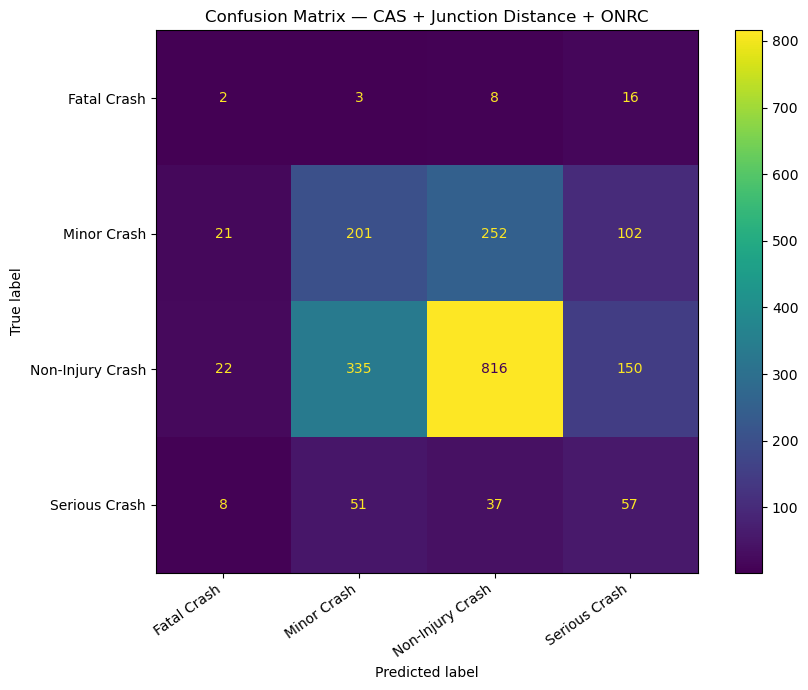


Fatal Crash predictions:
Serious Crash       16
Non-Injury Crash     8
Minor Crash          3
Fatal Crash          2
Name: count, dtype: int64

Serious Crash predictions:
Serious Crash       57
Minor Crash         51
Non-Injury Crash    37
Fatal Crash          8
Name: count, dtype: int64


In [61]:
# Confusion Matrix + Error Breakdown
# Final selected model

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

class_names = final_encoder.classes_

# Raw confusion matrix
cm = confusion_matrix(
    y_test_final_encoded,
    final_pred
)

cm_df = pd.DataFrame(
    cm,
    index=[f"Actual: {c}" for c in class_names],
    columns=[f"Predicted: {c}" for c in class_names]
)

print("Raw Confusion Matrix:")
display(cm_df)


# Row-normalised confusion matrix
cm_norm = confusion_matrix(
    y_test_final_encoded,
    final_pred,
    normalize="true"
)

cm_norm_df = pd.DataFrame(
    cm_norm,
    index=[f"Actual: {c}" for c in class_names],
    columns=[f"Predicted: {c}" for c in class_names]
)

print("\nRow-normalised Confusion Matrix:")
display(cm_norm_df.round(3))


# Plot raw confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(9, 7))

disp.plot(
    ax=ax,
    values_format="d"
)

plt.title(
    "Confusion Matrix — CAS + Junction Distance + ONRC"
)

plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


# Specific severe-class error breakdown
fatal_id = list(class_names).index("Fatal Crash")
serious_id = list(class_names).index("Serious Crash")

fatal_mask = y_test_final_encoded == fatal_id
serious_mask = y_test_final_encoded == serious_id

print("\nFatal Crash predictions:")
print(
    pd.Series(
        final_encoder.inverse_transform(
            final_pred[fatal_mask]
        )
    ).value_counts()
)

print("\nSerious Crash predictions:")
print(
    pd.Series(
        final_encoder.inverse_transform(
            final_pred[serious_mask]
        )
    ).value_counts()
)

In [62]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.


In [63]:
# SHAP setup + output-shape check

import shap
import numpy as np
import pandas as pd

print("SHAP version:", shap.__version__)

# Get transformed feature names
final_feature_names = (
    final_preprocessor
    .get_feature_names_out()
)

print("Number of transformed features:",
      len(final_feature_names))

print("\nFirst 20 transformed features:")
print(final_feature_names[:20])


# Create SHAP explainer
explainer = shap.TreeExplainer(
    final_model
)

shap_values = explainer.shap_values(
    X_test_final_processed
)

print("\nSHAP object type:")
print(type(shap_values))

if isinstance(shap_values, list):
    print("Number of class arrays:",
          len(shap_values))

    for i, arr in enumerate(shap_values):
        print(
            final_encoder.classes_[i],
            np.asarray(arr).shape
        )

else:
    print(
        "SHAP array shape:",
        np.asarray(shap_values).shape
    )

SHAP version: 0.52.0
Number of transformed features: 100

First 20 transformed features:
['num__bicycle' 'num__bus' 'num__carStationWagon' 'num__crashYear'
 'num__moped' 'num__motorcycle' 'num__NumberOfLanes'
 'num__otherVehicleType' 'num__schoolBus' 'num__speedLimit' 'num__suv'
 'num__taxi' 'num__truck' 'num__unknownVehicleType' 'num__vanOrUtility'
 'num__dist_to_junction_m' 'cat__crashDirectionDescription_East'
 'cat__crashDirectionDescription_North'
 'cat__crashDirectionDescription_Null'
 'cat__crashDirectionDescription_South']

SHAP object type:
<class 'numpy.ndarray'>
SHAP array shape: (2081, 100, 4)


### State Highway SHAP Method

This analysis explains the fitted State Highway model. For each original predictor, importance is calculated by summing the mean absolute SHAP values of its encoded columns. Global importance is also averaged across the four class outputs.

The final national analysis in Notebook 08 uses a different grouping method: signed SHAP contributions are summed within each original predictor before calculating mean absolute importance. The methods can produce different rankings because signed contributions can cancel within a predictor.

Interpret these State Highway rankings within this experiment. SHAP magnitudes should not be compared directly with the national results because both the grouping method and the crash population differ.

SHAP describes model behaviour and does not establish causal effects.

In [64]:
# SHAP Global + Class-Specific Feature Importance
# Aggregate one-hot columns back to original features

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


feature_names = np.array(
    final_preprocessor.get_feature_names_out()
)

class_names = final_encoder.classes_

print("Classes:")
for i, c in enumerate(class_names):
    print(i, c)

# Map transformed features -> original feature names


def get_original_feature(transformed_name):

    # Numeric features
    if transformed_name.startswith("num__"):
        return transformed_name.replace("num__", "", 1)

    # Categorical one-hot features
    if transformed_name.startswith("cat__"):

        clean_name = transformed_name.replace("cat__", "", 1)

        # Match longest feature name first
        for col in sorted(
            final_categorical,
            key=len,
            reverse=True
        ):
            if clean_name.startswith(col + "_"):
                return col

    return transformed_name


original_feature_names = [
    get_original_feature(name)
    for name in feature_names
]

print("\nNumber of transformed features:",
      len(feature_names))

print("Number of original feature groups:",
      len(set(original_feature_names)))

# Function to aggregate mean absolute SHAP values


def aggregate_shap_importance(
    shap_matrix,
    original_names
):

    importance_df = pd.DataFrame({
        "Feature": original_names,
        "MeanAbsSHAP": np.abs(
            shap_matrix
        ).mean(axis=0)
    })

    return (
        importance_df
        .groupby("Feature", as_index=False)
        ["MeanAbsSHAP"]
        .sum()
        .sort_values(
            "MeanAbsSHAP",
            ascending=False
        )
        .reset_index(drop=True)
    )

# GLOBAL importance
# Average SHAP magnitude across all 4 classes


global_shap_matrix = np.abs(
    shap_values
).mean(axis=2)

global_importance = aggregate_shap_importance(
    global_shap_matrix,
    original_feature_names
)

print("\nTOP 20 GLOBAL FEATURES:")
display(
    global_importance.head(20)
)

# FATAL class

fatal_index = list(
    class_names
).index("Fatal Crash")

fatal_importance = aggregate_shap_importance(
    shap_values[:, :, fatal_index],
    original_feature_names
)

print("\nTOP 20 FEATURES — FATAL CRASH:")
display(
    fatal_importance.head(20)
)

# SERIOUS class

serious_index = list(
    class_names
).index("Serious Crash")

serious_importance = aggregate_shap_importance(
    shap_values[:, :, serious_index],
    original_feature_names
)

print("\nTOP 20 FEATURES — SERIOUS CRASH:")
display(
    serious_importance.head(20)
)

# Specifically inspect spatial/context features

features_of_interest = [
    "dist_to_junction_m",
    "SH_ONRC"
]

print("\nSELECTED SPATIAL / ROAD FEATURES:")

for feature in features_of_interest:

    global_value = global_importance.loc[
        global_importance["Feature"] == feature,
        "MeanAbsSHAP"
    ]

    fatal_value = fatal_importance.loc[
        fatal_importance["Feature"] == feature,
        "MeanAbsSHAP"
    ]

    serious_value = serious_importance.loc[
        serious_importance["Feature"] == feature,
        "MeanAbsSHAP"
    ]

    print(f"\n{feature}")

    print(
        " Global:",
        global_value.iloc[0]
        if len(global_value) else "Not found"
    )

    print(
        " Fatal:",
        fatal_value.iloc[0]
        if len(fatal_value) else "Not found"
    )

    print(
        " Serious:",
        serious_value.iloc[0]
        if len(serious_value) else "Not found"
    )

Classes:
0 Fatal Crash
1 Minor Crash
2 Non-Injury Crash
3 Serious Crash

Number of transformed features: 100
Number of original feature groups: 32

TOP 20 GLOBAL FEATURES:


,Feature,MeanAbsSHAP
0,dist_to_junction_m,0.271559
1,region,0.202268
2,roadLane,0.171007
3,light,0.153597
4,SH_ONRC,0.144977
5,crashDirectionDescription,0.142671
6,motorcycle,0.113704
7,directionRoleDescription,0.105712
8,truck,0.099652
9,weatherA,0.095950



TOP 20 FEATURES — FATAL CRASH:


,Feature,MeanAbsSHAP
0,dist_to_junction_m,0.563889
1,region,0.345444
2,crashDirectionDescription,0.325339
3,roadLane,0.297938
4,light,0.291335
5,truck,0.208903
6,SH_ONRC,0.189722
7,trafficControl,0.178610
8,directionRoleDescription,0.173661
9,crashFinancialYear,0.146408



TOP 20 FEATURES — SERIOUS CRASH:


,Feature,MeanAbsSHAP
0,dist_to_junction_m,0.234658
1,region,0.218263
2,SH_ONRC,0.155245
3,directionRoleDescription,0.143954
4,motorcycle,0.141480
5,light,0.132942
6,weatherA,0.130892
7,crashDirectionDescription,0.113763
8,streetLight,0.101243
9,roadLane,0.086161



SELECTED SPATIAL / ROAD FEATURES:

dist_to_junction_m
 Global: 0.27155945
 Fatal: 0.56388944
 Serious: 0.23465845

SH_ONRC
 Global: 0.14497685
 Fatal: 0.18972151
 Serious: 0.1552449


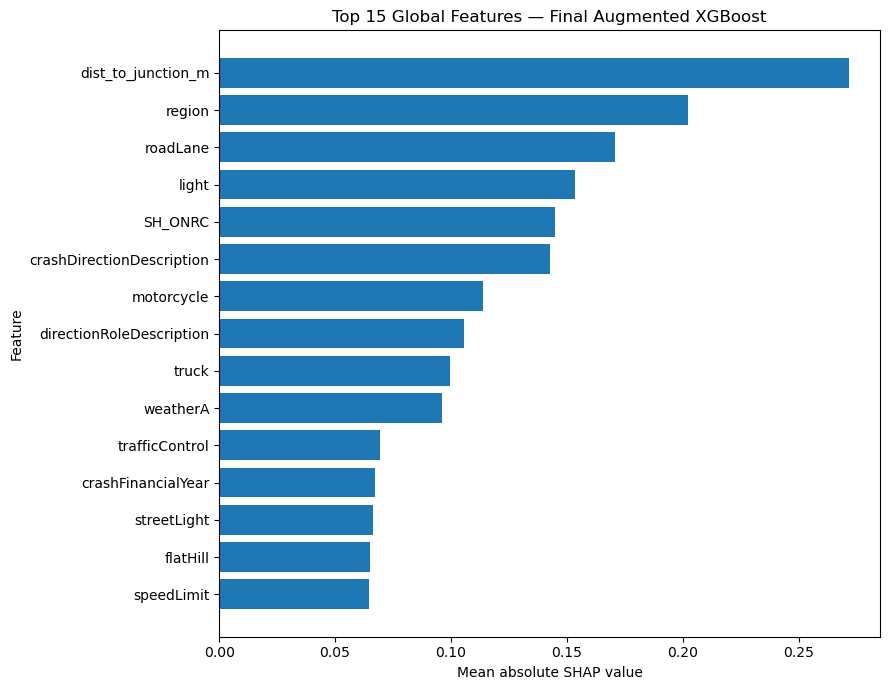

In [65]:
# Plot top 15 global SHAP features

top_global = (
    global_importance
    .head(15)
    .sort_values(
        "MeanAbsSHAP",
        ascending=True
    )
)

plt.figure(figsize=(9, 7))

plt.barh(
    top_global["Feature"],
    top_global["MeanAbsSHAP"]
)

plt.xlabel("Mean absolute SHAP value")
plt.ylabel("Feature")

plt.title(
    "Top 15 Global Features — Final Augmented XGBoost"
)

plt.tight_layout()
plt.show()

SHAP analysis showed that distance to the derived road-network junction was the most influential feature in the selected augmented XGBoost model. The external State Highway ONRC classification also ranked among the five most influential predictors, indicating that spatial topology and road-network context contributed meaningful predictive information beyond the original CAS variables.

,Distance_to_Junction_m,Fatal_SHAP,Serious_SHAP
count,2081.000000,2081.000000,2081.000000
mean,1104.265444,-0.540538,-0.121222
std,2016.054366,0.372775,0.273304
min,0.736252,-1.614924,-1.040187
25%,134.424280,-0.801501,-0.300220
50%,363.956983,-0.503998,-0.103115
75%,1266.548347,-0.295300,0.071860
max,23753.334608,1.023629,0.629524


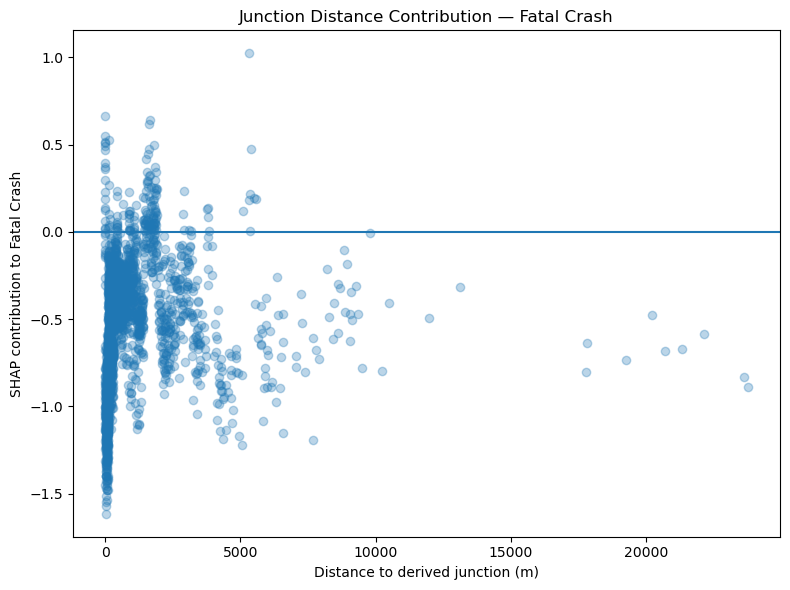

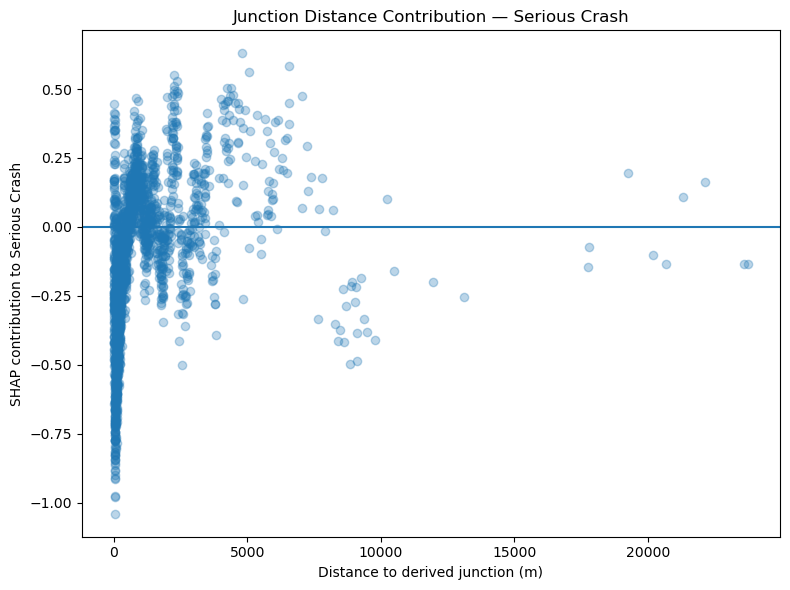

In [66]:
# SHAP direction analysis:
# Junction distance for Fatal and Serious crashes


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

feature_names = np.array(
    final_preprocessor.get_feature_names_out()
)

junction_idx = np.where(
    feature_names == "num__dist_to_junction_m"
)[0][0]

fatal_idx = list(
    final_encoder.classes_
).index("Fatal Crash")

serious_idx = list(
    final_encoder.classes_
).index("Serious Crash")


junction_direction_df = pd.DataFrame({
    "Distance_to_Junction_m":
        X_test_final["dist_to_junction_m"].to_numpy(),

    "Fatal_SHAP":
        shap_values[:, junction_idx, fatal_idx],

    "Serious_SHAP":
        shap_values[:, junction_idx, serious_idx]
})


display(
    junction_direction_df.describe()
)


# Fatal
plt.figure(figsize=(8, 6))

plt.scatter(
    junction_direction_df["Distance_to_Junction_m"],
    junction_direction_df["Fatal_SHAP"],
    alpha=0.3
)

plt.axhline(0)

plt.xlabel("Distance to derived junction (m)")
plt.ylabel("SHAP contribution to Fatal Crash")

plt.title(
    "Junction Distance Contribution — Fatal Crash"
)

plt.tight_layout()
plt.show()


# Serious
plt.figure(figsize=(8, 6))

plt.scatter(
    junction_direction_df["Distance_to_Junction_m"],
    junction_direction_df["Serious_SHAP"],
    alpha=0.3
)

plt.axhline(0)

plt.xlabel("Distance to derived junction (m)")
plt.ylabel("SHAP contribution to Serious Crash")

plt.title(
    "Junction Distance Contribution — Serious Crash"
)

plt.tight_layout()
plt.show()

In [67]:
# SHAP direction analysis for SH_ONRC categories

import numpy as np
import pandas as pd

feature_names = np.array(
    final_preprocessor.get_feature_names_out()
)

# Find all one-hot encoded ONRC columns
onrc_indices = np.where(
    np.char.startswith(
        feature_names.astype(str),
        "cat__SH_ONRC_"
    )
)[0]

print("ONRC transformed features:")
print(feature_names[onrc_indices])


fatal_idx = list(
    final_encoder.classes_
).index("Fatal Crash")

serious_idx = list(
    final_encoder.classes_
).index("Serious Crash")


# Total ONRC contribution for each test crash
fatal_onrc_shap = (
    shap_values[:, onrc_indices, fatal_idx]
    .sum(axis=1)
)

serious_onrc_shap = (
    shap_values[:, onrc_indices, serious_idx]
    .sum(axis=1)
)


onrc_direction_df = pd.DataFrame({
    "ONRC": X_test_final["SH_ONRC"].to_numpy(),
    "Fatal_ONRC_SHAP": fatal_onrc_shap,
    "Serious_ONRC_SHAP": serious_onrc_shap
})


fatal_onrc_summary = (
    onrc_direction_df
    .groupby("ONRC")["Fatal_ONRC_SHAP"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

serious_onrc_summary = (
    onrc_direction_df
    .groupby("ONRC")["Serious_ONRC_SHAP"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)


print("\nONRC contribution — Fatal Crash:")
display(fatal_onrc_summary.round(4))

print("\nONRC contribution — Serious Crash:")
display(serious_onrc_summary.round(4))

ONRC transformed features:
['cat__SH_ONRC_Access' 'cat__SH_ONRC_Arterial' 'cat__SH_ONRC_High Volume'
 'cat__SH_ONRC_National' 'cat__SH_ONRC_Primary Collector'
 'cat__SH_ONRC_Regional' 'cat__SH_ONRC_Secondary Collector'
 'cat__SH_ONRC_None']

ONRC contribution — Fatal Crash:


,count,mean,median
ONRC,,,
Access,2,0.0335,0.0335
National,298,0.0102,0.0076
Arterial,253,-0.0070,-0.0122
Regional,429,-0.0975,-0.0875
Primary Collector,355,-0.1624,-0.1450
High Volume,687,-0.1984,-0.2006
Secondary Collector,25,-0.5916,-0.5981



ONRC contribution — Serious Crash:


,count,mean,median
ONRC,,,
Secondary Collector,25,0.1757,0.1496
Primary Collector,355,0.0984,0.1055
Regional,429,0.0448,0.0447
Access,2,0.0105,0.0105
Arterial,253,-0.0479,-0.0507
National,298,-0.0570,-0.0534
High Volume,687,-0.1735,-0.1712


In [68]:
# Include None/missing ONRC category in the summary

onrc_direction_df_fixed = onrc_direction_df.copy()

onrc_direction_df_fixed["ONRC"] = (
    onrc_direction_df_fixed["ONRC"]
    .fillna("None")
)

print("ONRC contribution — Fatal Crash:")
display(
    onrc_direction_df_fixed
    .groupby("ONRC", dropna=False)["Fatal_ONRC_SHAP"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
    .round(4)
)

print("\nONRC contribution — Serious Crash:")
display(
    onrc_direction_df_fixed
    .groupby("ONRC", dropna=False)["Serious_ONRC_SHAP"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
    .round(4)
)

ONRC contribution — Fatal Crash:


,count,mean,median
ONRC,,,
Access,2,0.0335,0.0335
National,298,0.0102,0.0076
Arterial,253,-0.0070,-0.0122
None,32,-0.0216,-0.0198
Regional,429,-0.0975,-0.0875
Primary Collector,355,-0.1624,-0.1450
High Volume,687,-0.1984,-0.2006
Secondary Collector,25,-0.5916,-0.5981



ONRC contribution — Serious Crash:


,count,mean,median
ONRC,,,
Secondary Collector,25,0.1757,0.1496
Primary Collector,355,0.0984,0.1055
Regional,429,0.0448,0.0447
None,32,0.0427,0.0370
Access,2,0.0105,0.0105
Arterial,253,-0.0479,-0.0507
National,298,-0.0570,-0.0534
High Volume,687,-0.1735,-0.1712


ONRC road classification showed class-specific effects in the fitted model rather than a simple severity ordering. Primary Collector and Regional classifications tended to increase the model output for Serious crashes, whereas High Volume, National and Arterial classifications tended to reduce it. Fatal-class contributions followed a different pattern, with National approximately neutral and several other classes negative. These SHAP values describe model behaviour and should not be interpreted as causal effects or direct crash-risk estimates.

In [69]:
# RECOVER + EXPORT NATIONAL JUNCTION DISTANCE
# Uses:
#   CAS_Data_public.csv
#   saved AMDS_vehicle_network_2193.gpkg

from pathlib import Path
from collections import Counter

import pandas as pd
import numpy as np
import geopandas as gpd

from shapely.geometry import Point
from shapely.strtree import STRtree


# 1. Paths

CURRENT_FOLDER = Path.cwd()

PROJECT_ROOT = None

for folder in [CURRENT_FOLDER, *CURRENT_FOLDER.parents]:
    if (
        folder
        / "data"
        / "CAS_Data_public.csv"
    ).exists():
        PROJECT_ROOT = folder
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find the project root containing "
        "data/CAS_Data_public.csv."
    )


CAS_PATH = (
    PROJECT_ROOT
    / "data"
    / "CAS_Data_public.csv"
)

AMDS_PATH = (
    PROJECT_ROOT
    / "data"
    / "amds_network"
    / "AMDS_vehicle_network_2193.gpkg"
)

SPATIAL_DIR = (
    PROJECT_ROOT
    / "data"
    / "spatial"
)

SPATIAL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

OUTPUT_PATH = (
    SPATIAL_DIR
    / "CAS_Junction_enriched.csv"
)


print("Project root:", PROJECT_ROOT)
print("File Check")

print(
    "CAS exists:",
    CAS_PATH.exists()
)

print(
    "AMDS exists:",
    AMDS_PATH.exists()
)


if not CAS_PATH.exists():
    raise FileNotFoundError(
        f"CAS file not found:\n{CAS_PATH}"
    )

if not AMDS_PATH.exists():
    raise FileNotFoundError(
        f"AMDS file not found:\n{AMDS_PATH}"
    )


# 2. Load CAS

print(
    "\nLoading CAS..."
)

cas_local = pd.read_csv(
    CAS_PATH,
    low_memory=False
)

print(
    "CAS rows:",
    len(cas_local)
)


# Stable identifier based on original CAS row order

cas_local = (
    cas_local
    .reset_index(drop=True)
    .copy()
)

cas_local[
    "cas_row_id"
] = np.arange(
    len(cas_local),
    dtype=int
)


# Create crash point geometry

crash_gdf = gpd.GeoDataFrame(
    cas_local,
    geometry=gpd.points_from_xy(
        cas_local["X"],
        cas_local["Y"]
    ),
    crs="EPSG:2193"
)


# 3. Load saved AMDS vehicle network

print(
    "\nLoading saved AMDS network..."
)

roads_amds_clean = gpd.read_file(
    AMDS_PATH,
    layer="amds_vehicle_network"
)

print(
    "AMDS road segments:",
    len(roads_amds_clean)
)

print(
    "AMDS CRS:",
    roads_amds_clean.crs
)


if str(
    roads_amds_clean.crs
).upper() != "EPSG:2193":

    print(
        "Reprojecting AMDS to EPSG:2193..."
    )

    roads_amds_clean = (
        roads_amds_clean
        .to_crs(
            "EPSG:2193"
        )
    )


# 4. Explode possible MultiLineStrings

print(
    "\nPreparing road segments..."
)

amds_lines = (
    roads_amds_clean
    .explode(
        index_parts=False
    )
    .reset_index(drop=True)
)

print(
    "Road parts:",
    len(amds_lines)
)


# 5. Extract segment endpoints

print(
    "\nExtracting road endpoints..."
)

endpoint_coords = []

for geom in amds_lines.geometry:

    if (
        geom is None
        or geom.is_empty
    ):
        continue

    coords = list(
        geom.coords
    )

    start = coords[0]
    end = coords[-1]

    endpoint_coords.append(
        (
            round(start[0], 1),
            round(start[1], 1)
        )
    )

    endpoint_coords.append(
        (
            round(end[0], 1),
            round(end[1], 1)
        )
    )


endpoint_counts = Counter(
    endpoint_coords
)

print(
    "Total endpoints:",
    len(endpoint_coords)
)

print(
    "Unique endpoint locations:",
    len(endpoint_counts)
)


# 6. Junction definition

# Endpoint connected to at least 3 road segments

junction_coords = [
    coord
    for coord, count
    in endpoint_counts.items()
    if count >= 3
]

print(
    "\nNumber of junction candidates:",
    len(junction_coords)
)


junction_points = np.array(
    [
        Point(x, y)
        for x, y
        in junction_coords
    ],
    dtype=object
)


# 7. Nearest junction for every crash

print(
    "\nCalculating nearest junction distances..."
)

junction_tree = STRtree(
    junction_points
)

nearest_indices, junction_distances = (
    junction_tree.query_nearest(
        crash_gdf.geometry.to_numpy(),
        return_distance=True,
        all_matches=False
    )
)

crash_ids = (
    nearest_indices[0]
)

distances = np.full(
    len(crash_gdf),
    np.nan,
    dtype=float
)

distances[
    crash_ids
] = junction_distances

crash_gdf[
    "dist_to_junction_m"
] = distances

print(
    "Nearest junction calculation complete."
)


# 8. Final clean dataset

junction_final = (
    crash_gdf[
        [
            "cas_row_id",
            "dist_to_junction_m"
        ]
    ]
    .copy()
)


# 9. Validation

print(
    "JUNCTION VALIDATION"
)

print(
    "Rows:",
    len(junction_final)
)

print(
    "Unique crash IDs:",
    junction_final[
        "cas_row_id"
    ].nunique()
)

print(
    "Duplicate crash IDs:",
    junction_final[
        "cas_row_id"
    ].duplicated().sum()
)

print(
    "Missing junction distances:",
    junction_final[
        "dist_to_junction_m"
    ].isna().sum()
)

print(
    "\nJunction distance summary:"
)

print(
    junction_final[
        "dist_to_junction_m"
    ].describe()
)


# 10. Safety checks before saving

EXPECTED_ROWS = len(cas_local)

if len(junction_final) != EXPECTED_ROWS:

    raise ValueError(
        "Unexpected number of crashes. "
        "Do not save yet."
    )


if (
    junction_final[
        "cas_row_id"
    ].duplicated().sum()
    != 0
):

    raise ValueError(
        "Duplicate cas_row_id detected."
    )


if (
    junction_final[
        "dist_to_junction_m"
    ].isna().sum()
    != 0
):

    raise ValueError(
        "Missing junction distances detected."
    )


# 11. Save

junction_final.to_csv(
    OUTPUT_PATH,
    index=False
)

print(
    "\nSaved successfully:"
)

print(
    OUTPUT_PATH
)

print(
    "\nFinal shape:",
    junction_final.shape
)

Project root: C:\Users\ASUS\Desktop\Project_Roadcrash
File Check
CAS exists: True
AMDS exists: True

Loading CAS...
CAS rows: 34866

Loading saved AMDS network...
AMDS road segments: 262042
AMDS CRS: EPSG:2193

Preparing road segments...
Road parts: 262054

Extracting road endpoints...
Total endpoints: 524108
Unique endpoint locations: 324310

Number of junction candidates: 57522

Calculating nearest junction distances...
Nearest junction calculation complete.
JUNCTION VALIDATION
Rows: 34866
Unique crash IDs: 34866
Duplicate crash IDs: 0
Missing junction distances: 0

Junction distance summary:
count    34866.000000
mean       596.398671
std       1288.364947
min          0.190377
25%         47.395803
50%        160.575159
75%        554.228637
max      29411.830956
Name: dist_to_junction_m, dtype: float64

Saved successfully:
C:\Users\ASUS\Desktop\Project_Roadcrash\data\spatial\CAS_Junction_enriched.csv

Final shape: (34866, 2)
